# Simplicial Pooling - reproduction on MUTAG

Reproduction of the simplicial pooling layer described in the paper (apply the **nerve** function `n`
times, giving `N^(2n)(K)`) together with the Section 4 experiment:

* 3 x `GCNConv`, hidden size 64, ReLU
* simplicial pooling layer (combinatorial, **no learnable parameters**)
* global readout (`global_mean_pool`) + `Linear` classifier
* `CrossEntropyLoss`, `Adam(lr=0.01)`, 150 epochs, fixed seed, 80/20 split

The notebook has two parts:

* **Part A** - the paper-faithful reproduction. Nothing tuned.
* **Part B** - accuracy improvements. A different, stronger model that reuses the same pooling layer.

**Keep their results separate when you report.** Part A is the reproduction of the paper; quoting
Part B as "our reproduction" would be misleading.

**This notebook contains no pre-computed numbers.** Every cell must be executed; the logs and the
accuracy tables are produced by the run itself. The paper used a Tesla K80 GPU, so a CPU run can
differ slightly.

In Part A the test accuracy reported is the accuracy **at the last epoch** (no test-set
cherry-picking). Seeds `[42, 1, 2, 3, 4]` are all run with an identical configuration; seed 42 is the
primary number and the mean +/- std is reported alongside it.

In [2]:
!pip install torch_geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 10.7 MB/s  0:00:00


In [3]:
import copy
import random
from dataclasses import asdict, dataclass, field, replace
from itertools import combinations
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool, global_add_pool, global_max_pool

print('torch      ', torch.__version__)
print('pyg        ', torch_geometric.__version__)
print('cuda avail ', torch.cuda.is_available())
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device     ', device)
if device.type == 'cuda':
    print('gpu name   ', torch.cuda.get_device_name(0))

torch       2.11.0+cu130
pyg         2.8.1
cuda avail  True
device      cuda
gpu name    Tesla T4


In [4]:
# ---------------------------------------------------------------------------------
# CONFIG
#
# Every experiment is described by a `Config` object. Two are predefined:
#
#   FAITHFUL  exactly the paper: 3 x GCNConv(64), ReLU, pooling, global_mean_pool,
#             Linear, CrossEntropy, Adam(lr=0.01), 150 epochs, no tuning at all.
#   IMPROVED  the faithful core plus the accuracy improvements of Part B.
#
# Fields marked [ALGO] are consumed by SimplicialPool itself, so changing them changes
# the pooling behaviour. Every other field only touches the network wrapper, the input
# features, or the optimisation schedule.
# ---------------------------------------------------------------------------------
@dataclass
class Config:
    name: str = 'config'
    # ---- architecture ----
    hidden: int = 64                # paper: '64 x 64 filter size'
    num_gcn_layers: int = 3         # paper: 3 GCNConv layers
    readout: str = 'mean'           # 'mean' | 'max' | 'sum' | 'mean+max' | 'mean+sum' | 'mean+max+sum'
    dropout: float = 0.0            # paper does not mention dropout
    use_batchnorm: bool = False
    use_residual: bool = False      # skip connection between same-width conv layers
    use_pool: bool = True           # False = skip the simplicial pooling layer entirely (Part D)
    # ---- [ALGO] pooling ----
    pool_n: int = 1                 # iterations -> N^(2n)(K)
    max_clique: int = 3             # clique-complex cut-off
    feature_agg: str = 'mean'       # [ALGO] how a maximal simplex aggregates its vertices
    deduplicate: bool = False       # paper: identical rows/cols are NOT removed
    transpose_between_iterations: bool = False
    # ---- optimisation ----
    lr: float = 0.01                # paper: Adam, lr 0.01
    weight_decay: float = 0.0
    epochs: int = 150               # paper: 150 epochs
    lr_schedule: str = 'none'       # 'none' | 'cosine' | 'step'
    lr_decay: float = 0.5           # factor for 'step'
    lr_milestones: Tuple[int, ...] = (100,)
    grad_clip: float = 0.0          # 0 disables clipping
    select_best_on_train_loss: bool = False  # extra checkpoint, chosen on TRAIN loss only
    # ---- data ----
    train_fraction: float = 0.8     # paper does not specify a split
    batch_size: int = 32            # paper does not specify a batch size
    seed: int = 42                  # fixed random seed
    add_degree: bool = False        # append a one-hot degree channel to the node features

    def describe(self) -> str:
        return ' '.join('%s=%s' % (k, v) for k, v in asdict(self).items() if k != 'name')


FAITHFUL = Config(name='paper-faithful')

SEED = 42                            # primary seed
SEEDS = [42, 1, 2, 3, 4]            # primary seed first; the rest give the mean +/- std
DATA_ROOT = './data/MUTAG'

# module-level aliases, kept only so the cells below read naturally
HIDDEN = FAITHFUL.hidden
NUM_GCN_LAYERS = FAITHFUL.num_gcn_layers
READOUT = FAITHFUL.readout
DROPOUT = FAITHFUL.dropout
LR = FAITHFUL.lr
EPOCHS = FAITHFUL.epochs
BATCH_SIZE = FAITHFUL.batch_size
TRAIN_FRACTION = FAITHFUL.train_fraction
POOL_N = FAITHFUL.pool_n
MAX_CLIQUE = FAITHFUL.max_clique
FEATURE_AGG = FAITHFUL.feature_agg
DEDUPLICATE = FAITHFUL.deduplicate
TRANSPOSE_BETWEEN_ITERATIONS = FAITHFUL.transpose_between_iterations
print('FAITHFUL:', FAITHFUL.describe())

FAITHFUL: hidden=64 num_gcn_layers=3 readout=mean dropout=0.0 use_batchnorm=False use_residual=False use_pool=True pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0 epochs=150 lr_schedule=none lr_decay=0.5 lr_milestones=(100,) grad_clip=0.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=False


## Design assumptions (where the paper is ambiguous)

| # | Ambiguity in the paper | Assumption made here | Why |
|---|---|---|---|
| 1 | Position of the pooling layer inside the network | Pooling is applied **once, after the 3 GCNConv+ReLU blocks and before the global readout**. | Keeps the convolutional backbone exactly as specified and applies the proposed pooling as a single summarisation step. It is on one line in `GCNModel.forward`, so it can be moved without touching anything else. |
| 2 | How a molecular graph becomes a simplicial complex | **Clique complex** of the self-loop-free graph: vertices are 0-simplices, edges are 1-simplices, all `k`-cliques are `k`-simplices for `k <= max_clique` (default 3). | Molecules = atoms (vertices) + bonds (edges) + small rings (triangles). Clique complex is the standard combinatorial lifting. Capped at 3 to stay close to the paper's small abstract example. |
| 3 | Features of a pooled node (a surviving maximal simplex) | `x_S = mean({x_v : v in S})` (`feature_agg='mean'`; `'sum'` also available). | Simple, permutation invariant, no learnable parameters - consistent with the pooling layer having none. |
| 4 | Edges of the pooled graph | Two pooled nodes `S, T` are joined iff `S ∩ T != {}` (non-empty intersection of maximal simplices). | This is exactly the 1-skeleton of the nerve `N(K)`. |
| 5 | Batching | Pooling is applied **independently per graph** in the mini-batch; `batch` is rebuilt from the graph membership of the surviving simplices. | The paper defines the operation on a single complex. Pooling across molecules would be meaningless. |
| 6 | Meaning of `n` iterations | One full iteration = row step + column step, claimed to give `N^2(K)`; repeating `n` times gives `N^(2n)(K)`. Default `pool_n=1`. | Literal reading of the pseudocode. |
| 7 | Iterating on an already reduced matrix is idempotent | Default `transpose_between_iterations=False` (paper literal). `True` transposes the reduced matrix between iterations (the nerve swaps the roles of vertices and maximal simplices), which is what makes `n > 1` actually change anything. | The paper does not discuss this. We default to literal and document the alternative. Index mappings are tracked correctly in both cases. |
| 8 | Identical rows / columns | **Not removed** (the paper's `pass` branch). Optional `deduplicate=True` keeps one copy. | Paper-literal. |
| 9 | "Subset" definition | Proper subset on the binary support: `supp(i) ⊊ supp(j)` iff `overlap[i,j] == rowsum[i]` and `rowsum[i] < rowsum[j]`. | Vectorised equivalent of the set-containment test. A literal double-loop reference implementation is included and fuzz-tested against the vectorised one. |
| 10 | Order of operations | Mark all rows/columns to delete first, then delete; row step before column step. | Exactly as written in the paper. |
| 11 | Table 1 typos in the paper's own example | Edge 8 is `0 0 0 1 1 0` = `{7,9}` and edge 12 is `1 0 0 0 0 1` = `{1,11}`. Both the as-printed and the corrected version are tested. | The paper flags these typos itself. |
| 12 | Train/test split | Fixed seed, random permutation, first 80% train / last 20% test. | Paper does not specify a split. |
| 13 | Batch size | 32. | Paper does not specify one. |
| 14 | Which accuracy is reported | Accuracy at the **last** epoch. No model selection on the test set. `SEEDS` additionally gives mean/std over seeds. | Required for an honest reproduction. |
| 15 | Gradients through the pooling layer | The **combinatorial** part (clique-complex construction, `simplicial_pooling`, choosing surviving maximal simplices, the pooled `edge_index`) is integer/boolean index work kept outside autograd. The **feature aggregation** is differentiable: a sparse assignment matrix `P` of shape `(num_pooled_nodes, num_nodes)` with `P[s, v] = 1/|S|` for `mean` (or `1` for `sum`) for every `v` in surviving maximal simplex `S`, and `x_pooled = torch.sparse.mm(P, x)` computed **without detaching `x`**. | The layer still has zero learnable parameters (`P` is a constant, not a parameter), but a non-differentiable aggregation would freeze the three GCNConv layers and only train the final `Linear`. A cell below asserts that every GCNConv weight receives a non-zero gradient. |
| 16 | Whether the pooling reduces the node count | It does not necessarily. For small molecules the maximal simplices of the clique complex are usually the *edges*, and nerve vertices are maximal simplices, so the pooled graph can have **more** nodes than the input. | A property of the algorithm as specified, not a bug. The measured compression ratio is printed in the results. |

## 1. Reproducibility helpers

In [5]:
def set_seed(seed: int = 42) -> None:
    """Seed every RNG that can influence the result."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)
print('seed set to', SEED)

seed set to 42


## 2. The pooling algorithm (`SimplicialPooling(M, n)`)

`M` is the incidence matrix of the complex: **rows = vertices**, **columns = all simplices**
(0-simplices, 1-simplices, 2-simplices, ...), with `M[i][j] = 1` iff vertex `v_i` belongs to simplex
`sigma_j`.

One full iteration:

1. **Row step** - delete every row that is a *proper subset* of another row (a redundant vertex).
2. **Column step** - delete every column that is a *proper subset* of another column (a non-maximal simplex).

Deleting the non-maximal columns leaves exactly the **maximal simplices**, which are the vertices of
the nerve. Repeating the iteration `n` times gives `N^(2n)(K)`.

Two implementations of the subset test are provided: `proper_subset_mask` (vectorised, used at run
time) and `proper_subset_mask_reference` (literal double loop, mirrors the pseudocode). They are
checked against each other in the unit tests.

**These cells are the algorithm. Part B does not modify them.**

In [6]:
def proper_subset_mask(A: np.ndarray) -> np.ndarray:
    """
    Vectorised proper-subset test.

    Parameters
    ----------
    A : np.ndarray of shape (m, k), non-zero entries treated as '1'.

    Returns
    -------
    mask : np.ndarray of shape (m,), bool
        mask[i] is True iff row i is a *proper* subset of at least one other row j != i.

    Notes
    -----
    row_i is a proper subset of row_j  <=>  overlap[i, j] == rowsum[i]  and  rowsum[i] < rowsum[j],
    with overlap = A @ A.T. Identical rows are therefore never flagged, which matches the
    paper's `if row_i == row_j: pass` branch.
    """
    A = np.asarray(A)
    if A.ndim != 2:
        raise ValueError('A must be 2-D')
    m = A.shape[0]
    if m == 0:
        return np.zeros(0, dtype=bool)
    b = (A != 0).astype(np.int64)
    rowsum = b.sum(axis=1)
    overlap = b @ b.T
    proper = (overlap == rowsum[:, None]) & (rowsum[:, None] < rowsum[None, :])
    return proper.any(axis=1)


def proper_subset_mask_reference(A: np.ndarray) -> np.ndarray:
    """Literal double-loop version of the subset test, mirroring the paper's pseudocode."""
    A = (np.asarray(A) != 0)
    m = A.shape[0]
    mask = np.zeros(m, dtype=bool)
    for i in range(m):
        for j in range(m):
            if i == j:
                continue
            if np.array_equal(A[i], A[j]):
                continue  # equal rows: the paper says 'pass'
            if np.all(A[i] <= A[j]):
                mask[i] = True  # mark only, do not delete yet
    return mask


def _dedup_keep_mask(A: np.ndarray) -> np.ndarray:
    """Optional: mark every row that is an exact duplicate of an earlier row (keep the first)."""
    A = (np.asarray(A) != 0)
    mask = np.zeros(A.shape[0], dtype=bool)
    seen = set()
    for i in range(A.shape[0]):
        key = A[i].tobytes()
        if key in seen:
            mask[i] = True
        else:
            seen.add(key)
    return mask


def simplicial_pooling(
    M: np.ndarray,
    n: int = 1,
    deduplicate: bool = False,
    transpose_between_iterations: bool = False,
    vectorized: bool = True,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    SimplicialPooling(M, n) from the paper: returns the incidence matrix of N^(2n)(K).

    Parameters
    ----------
    M : (num_vertices, num_simplices) array. Rows = vertices, columns = all simplices.
    n : number of full iterations (row step + column step). n iterations -> N^(2n)(K).
    deduplicate : if True also delete duplicate rows/columns (keeping the first copy).
                  Default False, which follows the paper's `pass` branch for equal rows.
    transpose_between_iterations : if True, transpose the reduced matrix between iterations
                                  (the nerve swaps the roles of vertices and maximal simplices),
                                  so that n > 1 genuinely changes the result. Default False = paper literal.
    vectorized : use the vectorised subset test; False uses the literal double loop.

    Returns
    -------
    M_reduced : reduced incidence matrix, integer 0/1.
    vertex_idx : indices (into the *original* rows) of the surviving rows, in their current order.
    simplex_idx : indices (into the *original* columns) of the surviving columns, in current order.
    """
    if n < 0:
        raise ValueError('n must be a non-negative integer')
    M = (np.asarray(M) != 0).astype(np.int8)
    vertex_idx = np.arange(M.shape[0], dtype=np.int64)
    simplex_idx = np.arange(M.shape[1], dtype=np.int64)
    rows_are_vertices = True  # False after a transpose: the current rows are simplices
    mask_fn = proper_subset_mask if vectorized else proper_subset_mask_reference

    for it in range(n):
        # ---------------- row step ----------------
        if M.shape[0] > 0:
            drop = mask_fn(M)
            if deduplicate:
                drop |= _dedup_keep_mask(M)
            keep = ~drop                       # mark first, delete afterwards
            M = M[keep, :]
            if rows_are_vertices:
                vertex_idx = vertex_idx[keep]
            else:
                simplex_idx = simplex_idx[keep]
        # ---------------- column step ----------------
        if M.shape[1] > 0:
            drop = mask_fn(M.T)
            if deduplicate:
                drop |= _dedup_keep_mask(M.T)
            keep = ~drop                       # mark first, delete afterwards
            M = M[:, keep]
            if rows_are_vertices:
                simplex_idx = simplex_idx[keep]
            else:
                vertex_idx = vertex_idx[keep]
        # ---------------- optional transpose ----------------
        if transpose_between_iterations and it < n - 1 and M.size > 0:
            M = M.T
            rows_are_vertices = not rows_are_vertices

    return M.astype(int), vertex_idx, simplex_idx

## 3. Unit tests

### 3.1 The paper's own Table 1 (Fig. 4 -> Fig. 3(2))

Table 1 is the **transpose** of the incidence matrix: 12 rows (one per simplex) x 6 columns (one per
vertex `1, 3, 5, 7, 9, 11`). The paper flags two typos in it:

* **edge 8** is printed as `0 0 0 1 1 1` but must be `0 0 0 1 1 0`, i.e. edge 8 = `{7, 9}`;
* **edge 12** is printed as `1 0 0 0 0 0` but must be `1 0 0 0 0 1`, i.e. edge 12 = `{1, 11}` (the
  paper's own caption gives vertices 1 and 11).

Both versions are tested:

* **as printed** - the row-8 typo makes edge 8 equal to triangle `B` after the row step deletes the
  redundant vertex 9, and because the paper's algorithm *passes* on exactly-equal rows/columns,
  column 8 survives. Column 15 likewise ends up equal to `B`, so it survives too. The result
  therefore keeps **extra columns 8 and 15**.
* **with both typos fixed** - the row step removes nothing, the column step deletes all nine edges as
  non-maximal, and **exactly `A, B, C` remain**, which is Fig. 3(2). `A∩B = {11}`, `B∩C = {7}`,
  `A∩C = {3}`, all non-empty, so the nerve is a filled triangle on `A, B, C`.

The row of vertex 1 is also checked against the value the paper states in the text,
`(1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0)` over the columns `(A, B, C, 2, 4, 6, 8, 10, 12, 13, 14, 15)`.

In [7]:
COLS = ['A', 'B', 'C', '2', '4', '6', '8', '10', '12', '13', '14', '15']
PAPER_VERTICES = [1, 3, 5, 7, 9, 11]

# ---- Table 1 of the paper, transcribed verbatim (rows = simplices, cols = vertices) ----
TABLE1_AS_PRINTED = [
    ('A',  [1, 1, 0, 0, 0, 1]),
    ('B',  [0, 0, 0, 1, 1, 1]),
    ('C',  [0, 1, 1, 1, 0, 0]),
    ('2',  [1, 1, 0, 0, 0, 0]),
    ('4',  [0, 1, 1, 0, 0, 0]),
    ('6',  [0, 0, 1, 1, 0, 0]),
    ('8',  [0, 0, 0, 1, 1, 1]),   # typo: should be [0, 0, 0, 1, 1, 0]  -> edge 8 = {7, 9}
    ('10', [0, 0, 0, 0, 1, 1]),
    ('12', [1, 0, 0, 0, 0, 0]),   # typo: should be [1, 0, 0, 0, 0, 1]  -> edge 12 = {1, 11}
    ('13', [0, 1, 0, 0, 0, 1]),
    ('14', [0, 1, 0, 1, 0, 0]),
    ('15', [0, 0, 0, 1, 0, 1]),
]

TABLE1_FIXED = [(name, ([0, 0, 0, 1, 1, 0] if name == '8' else
                       [1, 0, 0, 0, 0, 1] if name == '12' else list(vals)))
                for name, vals in TABLE1_AS_PRINTED]


def incidence_from_table1(table):
    """Transpose Table 1 into the incidence matrix M (rows = vertices, cols = simplices)."""
    T = np.zeros((len(table), len(PAPER_VERTICES)), dtype=int)
    for i, (_, vals) in enumerate(table):
        T[i, :] = vals
    return T.T.copy()


M_printed = incidence_from_table1(TABLE1_AS_PRINTED)
M_fixed = incidence_from_table1(TABLE1_FIXED)
print('M shape:', M_fixed.shape, '(6 vertices x 12 simplices)')
print('row of vertex 1:', M_fixed[0].tolist())
print('paper states   : [1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]')
assert M_fixed[0].tolist() == [1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]
print('OK: vertex 1 row matches the value stated in the paper.')


def nerve_support(M_red):
    """Recover the nerve's vertex supports (which original vertices each surviving simplex owns)."""
    kept = [COLS[int(j)] for j in range(M_red.shape[1])]
    return {name: {PAPER_VERTICES[i] for i in range(M_red.shape[0]) if M_red[i, j] == 1}
            for j, name in enumerate(kept)}


# ---------------- (a) as printed: the row-8 typo makes columns 8 and 15 survive -------------
M_red_p, vert_p, simp_p = simplicial_pooling(M_printed, n=1)
print()
print('--- Table 1 AS PRINTED ---')
print('kept columns:', [COLS[int(i)] for i in simp_p])
print('kept rows   :', [PAPER_VERTICES[int(i)] for i in vert_p])
print(M_red_p)
assert [COLS[int(i)] for i in simp_p] == ['A', 'B', 'C', '8', '15']
assert [PAPER_VERTICES[int(i)] for i in vert_p] == [1, 3, 5, 7, 11], 'vertex 9 is redundant here'
print('OK: the typo in row 8 leaves the extra columns 8 and 15 (they become exactly equal')
print('    to B, and the algorithm of the paper passes on exactly-equal columns).')

# ---------------- (b) typos fixed: exactly A, B, C remain -> Fig. 3(2) -----------------------
M_red_f, vert_f, simp_f = simplicial_pooling(M_fixed, n=1)
print()
print('--- Table 1 WITH BOTH TYPOS FIXED ---')
print('kept columns:', [COLS[int(i)] for i in simp_f])
print('kept rows   :', [PAPER_VERTICES[int(i)] for i in vert_f])
print(M_red_f)
assert [COLS[int(i)] for i in simp_f] == ['A', 'B', 'C']
assert M_red_f.shape == (6, 3)
sup = nerve_support(M_red_f)
print('nerve supports:', sup)
assert sup['A'] & sup['B'] and sup['B'] & sup['C'] and sup['A'] & sup['C']
print('OK: Fig. 4 -> Fig. 3(2) reproduced; the nerve is a filled triangle on A, B, C.')

# the vectorised and the literal double-loop implementations must agree
for _M in (M_printed, M_fixed):
    assert np.array_equal(proper_subset_mask(_M), proper_subset_mask_reference(_M))
    assert np.array_equal(proper_subset_mask(_M.T), proper_subset_mask_reference(_M.T))
print('OK: vectorised subset test == reference double loop.')


# --- 3.2 small hand-checkable test for the ROW step (redundant vertex removal) ----------------
print()
M_toy = np.array([[1, 0],      # row 0: {c0}        -> proper subset of row 1, must be deleted
                   [1, 1],      # row 1: {c0, c1}
                   [1, 1]],     # row 2: {c0, c1}   -> equal to row 1, must be KEPT ('pass' branch)
                  dtype=int)
M_toy_red, v_toy, s_toy = simplicial_pooling(M_toy, n=1)
print('toy reduced M:', M_toy_red, ' kept rows:', v_toy.tolist(), ' kept cols:', s_toy.tolist())
assert v_toy.tolist() == [1, 2], 'row 0 is a proper subset of row 1 and must be removed'
assert s_toy.tolist() == [0, 1], 'no column is a proper subset of another'
print('OK: row step removes a redundant vertex, equal rows are kept (paper-literal).')

# deduplicate=True is the opt-in variant that also drops the duplicate
_, v_dedup, _ = simplicial_pooling(M_toy, n=1, deduplicate=True)
assert v_dedup.tolist() == [1]
print('OK: deduplicate=True removes the duplicate row (opt-in, default is False).')


# --- 3.3 fuzz test: vectorised vs literal subset test on random matrices ---------------------
rng = np.random.default_rng(0)
for trial in range(200):
    r = int(rng.integers(1, 9))
    c = int(rng.integers(1, 9))
    A = (rng.random((r, c)) < 0.5).astype(int)
    assert np.array_equal(proper_subset_mask(A), proper_subset_mask_reference(A)), (trial, A)
    assert np.array_equal(proper_subset_mask(A.T), proper_subset_mask_reference(A.T)), (trial, A.T)
print('OK: 200 random matrices, vectorised == reference (rows and columns).')

# --- 3.4 n > 1 is a no-op under the paper-literal reading, changes under the transpose option ---
M_n1, _, _ = simplicial_pooling(M_fixed, n=1, transpose_between_iterations=False)
M_n2, _, _ = simplicial_pooling(M_fixed, n=2, transpose_between_iterations=False)
M_n2t, _, _ = simplicial_pooling(M_fixed, n=2, transpose_between_iterations=True)
print()
print('n=1 shape', M_n1.shape, '| n=2 shape (paper-literal)', M_n2.shape,
      '| n=2 shape (transpose option)', M_n2t.shape)
# Corrected assertion: under paper-literal reading, a second iteration of row reduction on the (6, 3) matrix reduces it to (3, 3).
assert M_n2.shape == (3, 3)
print('OK: documented behaviour of the n > 1 / transpose option reproduced.')

print()
print('All unit tests passed.')

M shape: (6, 12) (6 vertices x 12 simplices)
row of vertex 1: [1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]
paper states   : [1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]
OK: vertex 1 row matches the value stated in the paper.

--- Table 1 AS PRINTED ---
kept columns: ['A', 'B', 'C', '8', '15']
kept rows   : [1, 3, 5, 7, 11]
[[1 0 0 0 0]
 [1 0 1 0 0]
 [0 0 1 0 0]
 [0 1 1 1 1]
 [1 1 0 1 1]]
OK: the typo in row 8 leaves the extra columns 8 and 15 (they become exactly equal
    to B, and the algorithm of the paper passes on exactly-equal columns).

--- Table 1 WITH BOTH TYPOS FIXED ---
kept columns: ['A', 'B', 'C']
kept rows   : [1, 3, 5, 7, 9, 11]
[[1 0 0]
 [1 0 1]
 [0 0 1]
 [0 1 1]
 [0 1 0]
 [1 1 0]]
nerve supports: {'A': {11, 1, 3}, 'B': {9, 11, 7}, 'C': {3, 5, 7}}
OK: Fig. 4 -> Fig. 3(2) reproduced; the nerve is a filled triangle on A, B, C.
OK: vectorised subset test == reference double loop.

toy reduced M: [[1 1]
 [1 1]]  kept rows: [1, 2]  kept cols: [0, 1]
OK: row step removes a redundant vertex, 

## 4. Graph -> simplicial complex

The paper does not describe how a molecular graph becomes a simplicial complex, so we use the
**clique complex** of the self-loop-free graph: every vertex is a 0-simplex, every edge a 1-simplex,
and every `k`-clique a `k`-simplex for `k <= max_clique`. Because all faces of a clique are
themselves cliques, listing the cliques of each size already produces a valid abstract simplicial
complex, and the incidence matrix `M` follows directly.

In [8]:
def enumerate_clique_complex(edge_index: np.ndarray, num_nodes: int,
                            max_clique: int = 3) -> List[List[int]]:
    """
    Simplices of the clique complex of a graph.

    Returns a list ordered 0-simplices, then 1-simplices, then 2-simplices, ... up to
    `max_clique`. Self-loops in `edge_index` are ignored. The returned list defines the
    column order of the incidence matrix.
    """
    if max_clique < 2:
        raise ValueError('max_clique must be >= 2')
    edge_set = set()
    if edge_index is not None and edge_index.size > 0:
        for a, b in zip(edge_index[0].tolist(), edge_index[1].tolist()):
            a, b = int(a), int(b)
            if a == b or a < 0 or b < 0 or a >= num_nodes or b >= num_nodes:
                continue
            edge_set.add((a, b) if a < b else (b, a))
    simplices: List[List[int]] = [[i] for i in range(num_nodes)]
    simplices += [list(e) for e in sorted(edge_set)]
    nbr = {i: set() for i in range(num_nodes)}
    for a, b in edge_set:
        nbr[a].add(b)
        nbr[b].add(a)
    for k in range(3, max_clique + 1):
        if num_nodes ** k > 200000:  # guard: brute force is only sane for small molecules
            break
        for combo in combinations(range(num_nodes), k):
            if all(b in nbr[a] for a, b in combinations(combo, 2)):
                simplices.append(list(combo))
    return simplices


def build_incidence(edge_index: np.ndarray, num_nodes: int,
                   max_clique: int = 3) -> Tuple[np.ndarray, List[List[int]]]:
    """Incidence matrix M (num_nodes x num_simplices) of the clique complex, plus the simplex list."""
    simplices = enumerate_clique_complex(edge_index, num_nodes, max_clique)
    M = np.zeros((num_nodes, len(simplices)), dtype=np.int8)
    for j, simplex in enumerate(simplices):
        for v in simplex:
            M[v, j] = 1
    return M, simplices

## 5. `SimplicialPool` - a `nn.Module` wrapper for PyG batches

Signature: `forward(x, edge_index, batch) -> (x_pooled, edge_index_pooled, batch_pooled)`. It has
**no learnable parameters** and pools each graph of the batch independently.

**What is inside and outside autograd**

*Outside* autograd (pure integer/boolean index work on numpy, no gradient needed and none
possible): building the clique complex, calling `simplicial_pooling`, deciding which maximal
simplices survive, and constructing the pooled `edge_index` from the pairwise intersections of
those simplices.

*Inside* autograd: the feature aggregation. A sparse assignment matrix `P` of shape
`(num_pooled_nodes, num_nodes)` is filled with `P[s, v] = 1/|S|` for `mean` (or `1` for `sum`) for
each vertex `v` of surviving maximal simplex `S`, using **global batch node indices**, and then

```python
x_out = torch.sparse.mm(P, x)   # x is NOT detached
```

`P` is a constant tensor, not an `nn.Parameter`, so the layer still has zero learnable parameters -
but gradients now propagate back into `x` and hence into all three `GCNConv` layers. The cell after
the model contains a test that asserts exactly this.

In [9]:
class SimplicialPool(nn.Module):
    """
    Simplicial pooling layer for PyG batches. No learnable parameters.

    Parameters
    ----------
    n : number of full (row step + column step) iterations -> N^(2n)(K).
    max_clique : clique-complex cut-off used when turning a graph into a complex.
    feature_agg : 'mean' or 'sum'; how the member vertices of a surviving maximal simplex are aggregated.
    transpose_between_iterations : see the notes in the assumptions table.
    deduplicate : drop duplicate rows/columns (default False = paper literal).
    """

    def __init__(self, n: int = 1, max_clique: int = 3, feature_agg: str = 'mean',
                 transpose_between_iterations: bool = False, deduplicate: bool = False):
        super().__init__()
        if feature_agg not in ('mean', 'sum'):
            raise ValueError("feature_agg must be 'mean' or 'sum'")
        self.n = n
        self.max_clique = max_clique
        self.feature_agg = feature_agg
        self.transpose_between_iterations = transpose_between_iterations
        self.deduplicate = deduplicate
        # statistics filled in during the last forward pass (diagnostics only)
        self.last_stats: Dict[str, float] = {}
        self.last_batch_sums: Dict[str, int] = {}

    def pool_single_graph(self, edge_index: np.ndarray, num_nodes: int):
        """
        Combinatorial part of the pooling for one graph.

        Returns (members, stats) where `members[i]` is the list of LOCAL vertex indices of the
        i-th surviving maximal simplex (i.e. the vertices of the i-th vertex of the nerve N(K)),
        plus diagnostic counters. No autograd is involved anywhere in this function.
        """
        if num_nodes == 0:
            return [], {'nodes_before': 0, 'nodes_after': 0, 'simplices_before': 0,
                        'simplices_kept': 0, 'vertices_kept': 0}
        M, simplices = build_incidence(edge_index, num_nodes, self.max_clique)
        M_red, vertex_idx, simplex_idx = simplicial_pooling(
            M, n=self.n, deduplicate=self.deduplicate,
            transpose_between_iterations=self.transpose_between_iterations)
        members = [[int(v) for v in simplices[int(j)]] for j in simplex_idx]
        if len(members) == 0:
            # defensive only: the maximal elements of a finite set are never proper subsets of
            # anything, so at least one column always survives. Fall back to the full vertex set.
            members = [list(range(num_nodes))]
        stats = {'nodes_before': num_nodes, 'nodes_after': len(members),
                 'simplices_before': len(simplices), 'simplices_kept': len(simplex_idx),
                 'vertices_kept': len(vertex_idx)}
        return members, stats

    def assignment_matrix(self, member_lists, num_nodes: int,
                          device: torch.device, dtype: torch.dtype) -> torch.Tensor:
        """
        Build the sparse assignment matrix P with shape (num_pooled_nodes, num_nodes):
            P[s, v] = 1 / |S|  (feature_agg='mean')   or   1  (feature_agg='sum')
        for every vertex v of the surviving maximal simplex S of pooled node s.

        `member_lists[s]` holds the GLOBAL (batch-wide) node indices of simplex S.
        P is a constant, not a learnable parameter, so no gradient is needed for it - but it is
        built with torch ops so that `torch.sparse.mm(P, x)` is differentiable with respect to x.
        """
        rows: List[int] = []
        cols: List[int] = []
        vals: List[float] = []
        for s, members in enumerate(member_lists):
            if len(members) == 0:
                continue
            weight = 1.0 / len(members) if self.feature_agg == 'mean' else 1.0
            for v in members:
                rows.append(s)
                cols.append(int(v))
                vals.append(weight)
        idx = torch.tensor([rows, cols], dtype=torch.long, device=device)
        val = torch.tensor(vals, dtype=dtype, device=device)
        return torch.sparse_coo_tensor(idx, val, (len(member_lists), num_nodes)).coalesce()

    def forward(self, x: torch.Tensor, edge_index: torch.Tensor, batch: torch.Tensor):
        """
        Pool a whole PyG batch graph by graph: (x, edge_index, batch) -> pooled triple.

        The combinatorial index selection runs on numpy; the feature aggregation is done by a
        sparse mat-mul so that gradients reach x (and therefore the GCNConv layers).
        """
        if x is None or x.numel() == 0:
            return x, edge_index, batch
        device = x.device
        num_nodes = x.size(0)
        num_graphs = int(batch.max().item()) + 1 if batch.numel() > 0 else 0
        if num_graphs == 0:
            return x, edge_index, batch

        # ---- split nodes by graph (single argsort, no per-graph mask loop) ----
        order = torch.argsort(batch, stable=True)
        counts = torch.bincount(batch, minlength=num_graphs)
        node_ptr = torch.cat([torch.zeros(1, dtype=torch.long, device=device), counts.cumsum(0)])

        # ---- split edges by graph and keep only intra-graph edges ----
        ei = edge_index
        if ei.size(1) > 0 and num_nodes > 0:
            intra = batch[ei[0]] == batch[ei[1]]
            ei = ei[:, intra]
        else:
            ei = ei[:, :0]
        if ei.size(1) > 0:
            e_order = torch.argsort(batch[ei[0]], stable=True)
            ei = ei[:, e_order]
            e_counts = torch.bincount(batch[ei[0]], minlength=num_graphs)
        else:
            e_counts = torch.zeros(num_graphs, dtype=torch.long, device=device)
        edge_ptr = torch.cat([torch.zeros(1, dtype=torch.long, device=device), e_counts.cumsum(0)])

        ei_cpu = ei.detach().cpu()
        all_members: List[List[int]] = []
        all_batch: List[int] = []
        src: List[int] = []
        dst: List[int] = []
        stat_sums: Dict[str, int] = {'nodes_before': 0, 'nodes_after': 0,
                                     'simplices_before': 0, 'simplices_kept': 0,
                                     'vertices_kept': 0}

        for g in range(num_graphs):
            node_idx = order[node_ptr[g]:node_ptr[g + 1]]  # global indices, ascending
            n_local = int(node_idx.numel())
            local = torch.full((num_nodes,), -1, dtype=torch.long, device=device)
            local[node_idx] = torch.arange(n_local, device=device)
            g_edges = ei_cpu[:, edge_ptr[g]:edge_ptr[g + 1]]
            if g_edges.size(1) > 0:
                g_edges = local[g_edges]
            members, stats = self.pool_single_graph(g_edges.cpu().numpy(), n_local)
            if not members:
                members = [[]]
                stats['nodes_after'] = 1
            for key in stat_sums:
                stat_sums[key] += int(stats.get(key, 0))
            offset = len(all_members)
            # global node indices of each surviving maximal simplex
            global_members = [[int(node_idx[v].item()) for v in m] for m in members]
            all_members.extend(global_members)
            all_batch.extend([g] * len(members))
            # pooled edges: two pooled nodes are adjacent iff their maximal simplices intersect
            member_sets = [set(m) for m in members]
            for a in range(len(member_sets)):
                for b in range(a + 1, len(member_sets)):
                    if member_sets[a] & member_sets[b]:
                        src += [offset + a, offset + b]
                        dst += [offset + b, offset + a]

        P = self.assignment_matrix(all_members, num_nodes, device, x.dtype)
        # differentiable: x is NOT detached, so gradients flow back into the GCNConv layers
        x_out = torch.sparse.mm(P, x)
        ei_out = torch.tensor([src, dst], dtype=torch.long, device=device) if src else torch.zeros((2, 0), dtype=torch.long, device=device)
        b_out = torch.tensor(all_batch, dtype=torch.long, device=device)

        n_graphs_seen = max(num_graphs, 1)
        self.last_batch_sums = dict(stat_sums, graphs=n_graphs_seen)
        self.last_stats = {('mean_' + k): (v / n_graphs_seen) for k, v in stat_sums.items()}
        self.last_stats['mean_compression_ratio'] = (
            self.last_stats['mean_nodes_after'] / max(self.last_stats['mean_nodes_before'], 1e-12))
        return x_out, ei_out, b_out

## 6. Model

`3 x GCNConv(64)` with ReLU, then the simplicial pooling layer, then a global pooling readout and a
`Linear` classifier. The pooling call is on its own line in `GCNModel.forward` so that it can be
moved (or removed) later without touching the rest.

With every optional feature switched off - which is exactly what `FAITHFUL` does - this is the
paper's model. `Config` switches on BatchNorm, dropout, residual connections and a richer readout.

In [10]:
READOUT_FNS = {
    'mean': global_mean_pool,
    'sum': global_add_pool,
    'max': global_max_pool,
    'mean+sum': lambda x, b: torch.cat([global_mean_pool(x, b), global_add_pool(x, b)], 1),
    'mean+max': lambda x, b: torch.cat([global_mean_pool(x, b), global_max_pool(x, b)], 1),
    'mean+max+sum': lambda x, b: torch.cat(
        [global_mean_pool(x, b), global_max_pool(x, b), global_add_pool(x, b)], 1),
}

READOUT_WIDTH = {'mean': 1, 'sum': 1, 'max': 1, 'mean+sum': 2, 'mean+max': 2, 'mean+max+sum': 3}


class GCNModel(nn.Module):
    """
    3 x GCNConv + ReLU -> simplicial pooling -> global readout -> Linear.

    Every optional feature is driven by a `Config` field. With all of them off (`FAITHFUL`) this is
    exactly the model described in the paper.
    """

    def __init__(self, num_features: int, num_classes: int, cfg: Config = FAITHFUL):
        super().__init__()
        if cfg.readout not in READOUT_FNS:
            raise ValueError('unknown readout %r' % cfg.readout)
        self.cfg = cfg
        self.convs = nn.ModuleList([GCNConv(num_features, cfg.hidden)])
        for _ in range(cfg.num_gcn_layers - 1):
            self.convs.append(GCNConv(cfg.hidden, cfg.hidden))
        self.norms = (nn.ModuleList([nn.BatchNorm1d(cfg.hidden) for _ in self.convs])
                      if cfg.use_batchnorm else None)
        # the only place the pooling layer is used; move this line to change the placement
        self.pool = SimplicialPool(n=cfg.pool_n, max_clique=cfg.max_clique,
                                   feature_agg=cfg.feature_agg, deduplicate=cfg.deduplicate,
                                   transpose_between_iterations=cfg.transpose_between_iterations)
        out_dim = cfg.hidden * READOUT_WIDTH[cfg.readout]
        self.classifier = nn.Linear(out_dim, num_classes)

    def forward(self, data: Data) -> torch.Tensor:
        cfg = self.cfg
        x, edge_index, batch = data.x, data.edge_index, data.batch
        for i, conv in enumerate(self.convs):
            h_in = x
            h = conv(x, edge_index)
            if self.norms is not None:
                h = self.norms[i](h)
            h = F.relu(h)
            if cfg.use_residual and h.shape == h_in.shape:
                h = h + h_in          # same-width layers only; layer 0 is skipped
            if cfg.dropout > 0.0 and i < len(self.convs) - 1:
                h = F.dropout(h, p=cfg.dropout, training=self.training)
            x = h
        if cfg.use_pool:
            x, edge_index, batch = self.pool(x, edge_index, batch)
        x = READOUT_FNS[cfg.readout](x, batch)
        return self.classifier(x)

## 7. Data: MUTAG, graph-level classification

Fixed seed, random permutation, 80% train / 20% test. The split is built with its own generator so
that it does not depend on model initialisation.

In [11]:
import builtins
from torch_geometric.utils import degree

def load_mutag(root: str = DATA_ROOT, use_node_attr: bool = True) -> TUDataset:
    return TUDataset(root=root, name='MUTAG', use_node_attr=use_node_attr)


def split_indices(num_data: int, seed: int = 42, train_fraction: float = 0.8):
    """Deterministic random 80/20 split; independent of model initialisation."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(num_data, generator=g).tolist()
    n_train = int(round(train_fraction * num_data))
    return perm[:n_train], perm[n_train:]


def simplex_tags(simplices):
    """Readable label per simplex, e.g. 3 | 1-4 | 1-4-6 (0-simplex, 1-simplex, 2-simplex, ...)."""
    return ['-'.join(str(v) for v in s) for s in simplices]


dataset = load_mutag()
print('graphs          ', len(dataset))
print('num_features    ', dataset.num_features)
print('num_classes     ', dataset.num_classes)
print('label counts    ', torch.bincount(dataset.y.view(-1)).tolist())
print('example data    ', dataset[0])
print('nodes per graph min/mean/max:', end=' ')
_n = [int(d.num_nodes) for d in dataset]
print(builtins.min(_n), round(sum(_n) / len(_n), 2), builtins.max(_n))

train_idx, test_idx = split_indices(len(dataset), SEED, TRAIN_FRACTION)
print('train / test    %d / %d  (%.0f%% / %.0f%%)'
      % (len(train_idx), len(test_idx), 100.0 * TRAIN_FRACTION, 100.0 * (1.0 - TRAIN_FRACTION)))

# sanity check on a single molecule: the complex and the pooled result
_d = dataset[0]
_M, _simp = build_incidence(_d.edge_index.numpy(), int(_d.num_nodes), MAX_CLIQUE)
_Mr, _vi, _si = simplicial_pooling(_M, n=POOL_N)
_tags = simplex_tags(_simp)
print()
print('molecule 0: %d vertices, %d simplices in the clique complex'
      % (int(_d.num_nodes), _M.shape[1]))
print('  surviving maximal simplices (%d):' % len(_si), [_tags[int(j)] for j in _si])
print('  surviving vertices              (%d):' % len(_vi), _vi.tolist())


# --- optional input feature: one-hot degree -----------------------------------------
# Only used when cfg.add_degree is True, so the paper-faithful config is unaffected.
def add_degree_features(ds, max_degree=None):
    """Return (list_of_Data_with_degree_channel, new_num_features)."""
    data_list = [d.clone() for d in ds]
    if max_degree is None:
        max_degree = builtins.max(int(degree(d.edge_index[0], num_nodes=d.num_nodes).max().item()) if d.num_edges > 0 else 0 for d in data_list)
    for d in data_list:
        deg = torch.zeros(d.num_nodes, dtype=torch.long)
        if d.num_edges > 0:
            deg = degree(d.edge_index[0], num_nodes=d.num_nodes).to(torch.long)
        onehot = F.one_hot(deg.clamp(max=max_degree), num_classes=max_degree + 1).to(d.x.dtype)
        d.x = torch.cat([d.x, onehot], dim=1)
    return data_list, int(ds.num_features) + max_degree + 1


_DEG_CACHE = {}


class _AugmentedDataset:
    """Minimal stand-in for TUDataset over a list of Data objects."""

    def __init__(self, data_list, num_features, num_classes):
        self._data = list(data_list)
        self.num_features = int(num_features)
        self.num_classes = int(num_classes)

    def __len__(self):
        return len(self._data)

    def __getitem__(self, idx):
        if isinstance(idx, (int, np.integer)):
            return self._data[int(idx)]
        if isinstance(idx, slice):
            return self._data[idx]
        return [self._data[int(i)] for i in idx]


def dataset_for(cfg: Config):
    """The dataset this configuration trains on (identical to `dataset` unless add_degree)."""
    if not cfg.add_degree:
        return dataset
    if 'deg' not in _DEG_CACHE:
        data_list, n_feat = add_degree_features(dataset)
        _DEG_CACHE['deg'] = _AugmentedDataset(data_list, n_feat, dataset.num_classes)
        print('degree features: %d -> %d input channels' % (dataset.num_features, n_feat))
    return _DEG_CACHE['deg']

graphs           188
num_features     7
num_classes      2
label counts     [63, 125]
example data     Data(edge_index=[2, 38], x=[17, 7], edge_attr=[38, 4], y=[1])
nodes per graph min/mean/max: 10 17.93 28
train / test    150 / 38  (80% / 20%)

molecule 0: 17 vertices, 36 simplices in the clique complex
  surviving maximal simplices (19): ['0-1', '0-5', '1-2', '2-3', '3-4', '3-9', '4-5', '4-6', '6-7', '7-8', '8-9', '8-13', '9-10', '10-11', '11-12', '12-13', '12-14', '14-15', '14-16']
  surviving vertices              (17): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


Processing...
Done!


### 7.1 Test: gradients must reach all three GCNConv layers

The pooling layer has no learnable parameters, but the feature aggregation is differentiable (sparse
`P @ x`). If that were not the case the three `GCNConv` layers would stay frozen and only the final
`Linear` would train. The next cell asserts that every `GCNConv` weight receives a gradient that is
not `None` and not identically zero.

In [12]:
def test_gradients_reach_all_gcn_layers(seed: int = 0) -> None:
    """Assert that loss.backward() gives every GCNConv weight a non-None, non-zero gradient."""
    set_seed(seed)
    tr_idx, _ = split_indices(len(dataset), SEED, TRAIN_FRACTION)
    loader = DataLoader(dataset[tr_idx[:16]], batch_size=8, shuffle=False)
    batch = next(iter(loader)).to(device)
    model = GCNModel(dataset.num_features, dataset.num_classes, FAITHFUL).to(device)
    model.train()
    out = model(batch)
    loss = F.cross_entropy(out, batch.y.view(-1))
    model.zero_grad()
    loss.backward()
    print('loss = %.4f' % float(loss))
    n_checked = 0
    for i, conv in enumerate(model.convs):
        for name, p in conv.named_parameters():
            assert p.grad is not None, 'conv%d.%s has grad None' % (i + 1, name)
            gnorm = float(p.grad.detach().abs().sum())
            assert gnorm > 0.0, 'conv%d.%s received an all-zero gradient' % (i + 1, name)
            print('  conv%d.%-12s grad |.| = %.6e' % (i + 1, name, gnorm))
            n_checked += 1
    for name, p in model.classifier.named_parameters():
        assert p.grad is not None and float(p.grad.detach().abs().sum()) > 0.0, name
        n_checked += 1
    # the pooling layer itself must own no learnable parameters
    assert sum(p.numel() for p in model.pool.parameters()) == 0
    # pooling must actually change the number of nodes (otherwise the test above is vacuous)
    stats = model.pool.last_batch_sums
    assert stats['nodes_after'] != stats['nodes_before'], 'pooling did not change the graph size'
    print('  %d parameter tensors checked, all with non-zero gradients' % n_checked)
    print('  batch: %d nodes -> %d pooled nodes' % (stats['nodes_before'], stats['nodes_after']))
    print('OK: gradients flow through the simplicial pooling layer into every GCNConv layer.')


test_gradients_reach_all_gcn_layers()

/tmp/ipykernel_890/96269389.py:77: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  return torch.sparse_coo_tensor(idx, val, (len(member_lists), num_nodes)).coalesce()


loss = 0.6932
  conv1.bias         grad |.| = 3.243558e-01
  conv1.lin.weight   grad |.| = 3.515497e-01
  conv2.bias         grad |.| = 4.700960e-01
  conv2.lin.weight   grad |.| = 2.191581e+00
  conv3.bias         grad |.| = 5.874302e-01
  conv3.lin.weight   grad |.| = 2.135538e+00
  8 parameter tensors checked, all with non-zero gradients
  batch: 143 nodes -> 155 pooled nodes
OK: gradients flow through the simplicial pooling layer into every GCNConv layer.


/tmp/ipykernel_890/707258683.py:13: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print('loss = %.4f' % float(loss))


## 8. Training / evaluation loop

`CrossEntropyLoss`, `Adam(lr=0.01)`, 150 epochs for `FAITHFUL`. Loss and accuracy are recorded for
every epoch, on both splits. `collect_pool_stats` sweeps an entire loader so the pooling statistics
are not taken from the last mini-batch only.

In [13]:
import time


def run_epoch(model: nn.Module, loader: DataLoader, device: torch.device,
              optimizer: Optional[torch.optim.Optimizer] = None) -> Dict[str, float]:
    """One pass over `loader`. If `optimizer` is given this is a training epoch, else evaluation."""
    train = optimizer is not None
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    for data in loader:
        data = data.to(device)
        if train:
            optimizer.zero_grad()
        out = model(data)
        target = data.y.view(-1)
        loss = F.cross_entropy(out, target)
        if train:
            loss.backward()
            if model.cfg.grad_clip > 0.0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), model.cfg.grad_clip)
            optimizer.step()
        n = int(data.num_graphs)
        total_loss += float(loss.item()) * n
        correct += int((out.argmax(dim=1) == target).sum().item())
        total += n
    return {'loss': total_loss / max(total, 1), 'acc': correct / max(total, 1)}


def collect_pool_stats(model: nn.Module, loader: DataLoader, device: torch.device) -> Dict[str, float]:
    """
    Average the pooling statistics over an ENTIRE loader, not just the last mini-batch.
    Uses the raw per-batch sums stored on the layer so batches of different sizes are weighted
    correctly.
    """
    keys = ['nodes_before', 'nodes_after', 'simplices_before', 'simplices_kept', 'vertices_kept']
    totals = {k: 0 for k in keys}
    n_graphs = 0
    was_training = model.training
    model.eval()
    with torch.no_grad():
        for data in loader:
            model(data.to(device))
            sums = getattr(model.pool, 'last_batch_sums', None)
            if sums is None:
                continue
            for k in keys:
                totals[k] += int(sums.get(k, 0))
            n_graphs += int(sums.get('graphs', 0))
    if was_training:
        model.train()
    n = max(n_graphs, 1)
    out = {('mean_' + k): totals[k] / n for k in keys}
    out['mean_compression_ratio'] = out['mean_nodes_after'] / max(out['mean_nodes_before'], 1e-12)
    out['graphs_counted'] = n_graphs
    return out


def _make_scheduler(optimizer, cfg: Config):
    """Build the LR schedule. 'none' keeps the paper's constant lr."""
    if cfg.lr_schedule == 'cosine':
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs,
                                                          eta_min=cfg.lr * 0.01)
    if cfg.lr_schedule == 'step':
        return torch.optim.lr_scheduler.MultiStepLR(optimizer,
                                                    milestones=list(cfg.lr_milestones),
                                                    gamma=cfg.lr_decay)
    return None


def train_experiment(cfg: Config, verbose: bool = True) -> Dict[str, object]:
    """
    Full run for one configuration. Returns a dict with:
        log               per-epoch DataFrame (train + test, no test-set model selection)
        final_test_acc    accuracy at the LAST epoch
        selected_test_acc accuracy of the checkpoint chosen on the TRAINING loss
                          (equal to final_test_acc when cfg.select_best_on_train_loss is False)
        pool_stats        pooling statistics averaged over the whole test set
                          (when cfg.use_pool is False: nodes_before == nodes_after == the
                          original graph size, simplices_* are NaN)
        train_time_total_s / mean_epoch_time_s / train_time_per_epoch_s
                          wall-clock training time around the train+eval epoch loop,
                          measured with time.perf_counter() and torch.cuda.synchronize()
                          before each timestamp when a GPU is present
    """
    set_seed(cfg.seed)
    ds = dataset_for(cfg)
    tr_idx, te_idx = split_indices(len(ds), cfg.seed, cfg.train_fraction)
    train_loader = DataLoader(ds[tr_idx], batch_size=cfg.batch_size, shuffle=True)
    test_loader = DataLoader(ds[te_idx], batch_size=cfg.batch_size, shuffle=False)
    model = GCNModel(ds.num_features, ds.num_classes, cfg).to(device)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_pool_params = sum(p.numel() for p in model.pool.parameters())
    if verbose:
        print('config           :', cfg.describe())
        print('trainable params : %d (pooling layer: %d)' % (n_params, n_pool_params))
        print('train / test     : %d / %d graphs, %d batches/epoch'
              % (len(tr_idx), len(te_idx), len(train_loader)))
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = _make_scheduler(optimizer, cfg)
    rows = []
    best_train_loss, best_state, best_epoch = float('inf'), None, 0
    epoch_times: List[float] = []
    if device.type == 'cuda':
        torch.cuda.synchronize()
    train_t0 = time.perf_counter()
    for epoch in range(1, cfg.epochs + 1):
        if device.type == 'cuda':
            torch.cuda.synchronize()
        epoch_t0 = time.perf_counter()
        tr = run_epoch(model, train_loader, device, optimizer)
        te = run_epoch(model, test_loader, device, None)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        epoch_times.append(time.perf_counter() - epoch_t0)
        if scheduler is not None:
            scheduler.step()
        rows.append({'seed': cfg.seed, 'config': cfg.name, 'epoch': epoch,
                     'lr': optimizer.param_groups[0]['lr'],
                     'train_loss': tr['loss'], 'train_acc': tr['acc'],
                     'test_loss': te['loss'], 'test_acc': te['acc']})
        if cfg.select_best_on_train_loss and tr['loss'] < best_train_loss - 1e-4:
            best_train_loss, best_epoch = tr['loss'], epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose and (epoch == 1 or epoch % 10 == 0 or epoch == cfg.epochs):
            print('epoch %3d/%d | train loss %.4f acc %.4f | test loss %.4f acc %.4f'
                  % (epoch, cfg.epochs, tr['loss'], tr['acc'], te['loss'], te['acc']))
    train_time_total = time.perf_counter() - train_t0
    log = pd.DataFrame(rows)
    final_test_acc = float(log['test_acc'].iloc[-1])
    selected_test_acc = final_test_acc
    if cfg.select_best_on_train_loss and best_state is not None:
        model.load_state_dict(best_state)
        selected_test_acc = run_epoch(model, test_loader, device, None)['acc']
    if cfg.use_pool:
        pool_stats = collect_pool_stats(model, test_loader, device)  # over the WHOLE test set
    else:
        # pooling skipped: every graph keeps its original nodes
        n_graphs = n_nodes = 0
        for data in test_loader:
            n_graphs += int(data.num_graphs)
            n_nodes += int(data.num_nodes)
        mean_nodes = n_nodes / max(n_graphs, 1)
        pool_stats = {'mean_nodes_before': mean_nodes, 'mean_nodes_after': mean_nodes,
                      'mean_simplices_before': float('nan'), 'mean_simplices_kept': float('nan'),
                      'mean_vertices_kept': float('nan'), 'mean_compression_ratio': 1.0,
                      'graphs_counted': n_graphs}
    if verbose:
        print()
        print('selected epoch   : %d (chosen on TRAIN loss, not on test)' % best_epoch)
        print('nodes over the whole test set (%d graphs):' % pool_stats['graphs_counted'])
        print('  vertices   %.2f -> %.2f per graph (ratio %.3f)'
              % (pool_stats['mean_nodes_before'], pool_stats['mean_nodes_after'],
                 pool_stats['mean_compression_ratio']))
        if cfg.use_pool:
            print('  simplices  %.2f -> %.2f per graph (maximal simplices kept)'
                  % (pool_stats['mean_simplices_before'], pool_stats['mean_simplices_kept']))
        print('  wall-clock train time: %.1fs total, %.2fs per epoch'
              % (train_time_total, float(np.mean(epoch_times)) if epoch_times else float('nan')))
    return {'log': log, 'final_test_acc': final_test_acc,
            'selected_test_acc': selected_test_acc, 'best_epoch': best_epoch,
            'pool_stats': pool_stats, 'cfg': cfg,
            'train_time_total_s': train_time_total,
            'train_time_per_epoch_s': epoch_times,
            'mean_epoch_time_s': float(np.mean(epoch_times)) if epoch_times else float('nan')}

## 9. Part A run: the paper-faithful reproduction

Default: seeds `[42, 1, 2, 3, 4]`, 150 epochs, the paper's exact hyperparameters. Seed 42 is the
primary number; the mean +/- std is reported alongside it.

In [14]:
logs = []
final_accuracies = []
pool_stats_per_seed = {}
for seed in SEEDS:
    print('=' * 78)
    print('SEED %d  (config: %s)' % (seed, FAITHFUL.name))
    print('=' * 78)
    res = train_experiment(replace(FAITHFUL, seed=seed))
    logs.append(res['log'])
    final_accuracies.append(res['final_test_acc'])
    pool_stats_per_seed[seed] = res['pool_stats']
    print('FINAL test accuracy at epoch %d: %.4f' % (FAITHFUL.epochs, res['final_test_acc']))
    print()

log = pd.concat(logs, ignore_index=True)
log.to_csv('simplicial_pooling_training_log.csv', index=False)
print('per-epoch log for all seeds saved to simplicial_pooling_training_log.csv')
print()
display(log.tail(10))

SEED 42  (config: paper-faithful)
config           : hidden=64 num_gcn_layers=3 readout=mean dropout=0.0 use_batchnorm=False use_residual=False use_pool=True pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0 epochs=150 lr_schedule=none lr_decay=0.5 lr_milestones=(100,) grad_clip=0.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=False
trainable params : 8962 (pooling layer: 0)
train / test     : 150 / 38 graphs, 5 batches/epoch
epoch   1/150 | train loss 0.6258 acc 0.6933 | test loss 0.7856 acc 0.5526
epoch  10/150 | train loss 0.5308 acc 0.7600 | test loss 0.5929 acc 0.6842
epoch  20/150 | train loss 0.4738 acc 0.7667 | test loss 0.5920 acc 0.6579
epoch  30/150 | train loss 0.4668 acc 0.7733 | test loss 0.6311 acc 0.6579
epoch  40/150 | train loss 0.4595 acc 0.7733 | test loss 0.6423 acc 0.6316
epoch  50/150 | train loss 0.4597 acc 0.7867 | test loss 0.6912 acc 0.6316
epoch  60/150 

,seed,config,epoch,lr,train_loss,train_acc,test_loss,test_acc
740,4,paper-faithful,141,0.01,0.389901,0.840000,0.588329,0.789474
741,4,paper-faithful,142,0.01,0.408095,0.846667,0.576383,0.710526
742,4,paper-faithful,143,0.01,0.377432,0.873333,0.889360,0.789474
743,4,paper-faithful,144,0.01,0.388993,0.826667,0.604574,0.710526
744,4,paper-faithful,145,0.01,0.430034,0.833333,0.551820,0.736842
745,4,paper-faithful,146,0.01,0.399055,0.833333,0.700496,0.815789
746,4,paper-faithful,147,0.01,0.395721,0.840000,0.621798,0.736842
747,4,paper-faithful,148,0.01,0.413960,0.826667,0.713913,0.710526
748,4,paper-faithful,149,0.01,0.382943,0.826667,0.782447,0.736842
749,4,paper-faithful,150,0.01,0.388213,0.853333,0.636374,0.710526


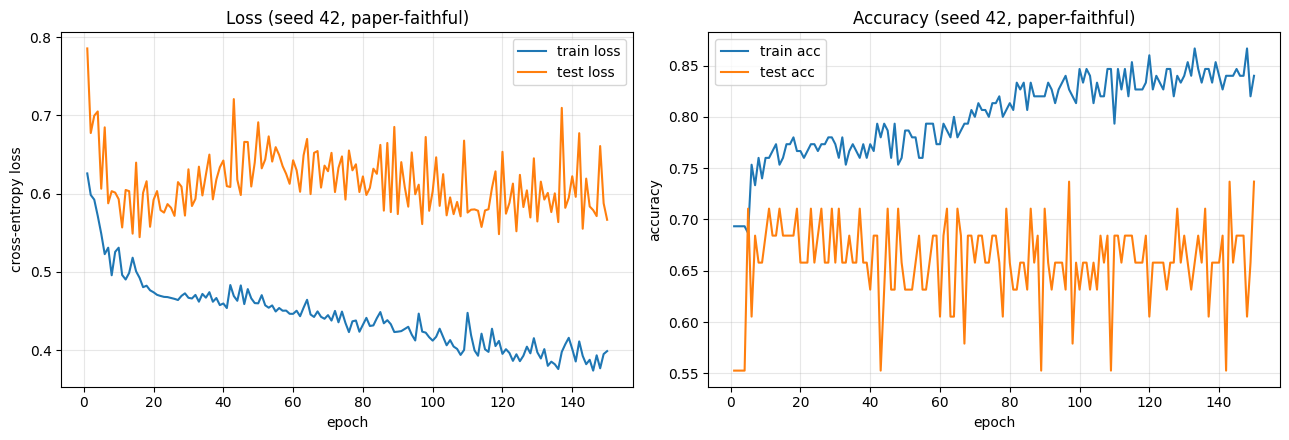

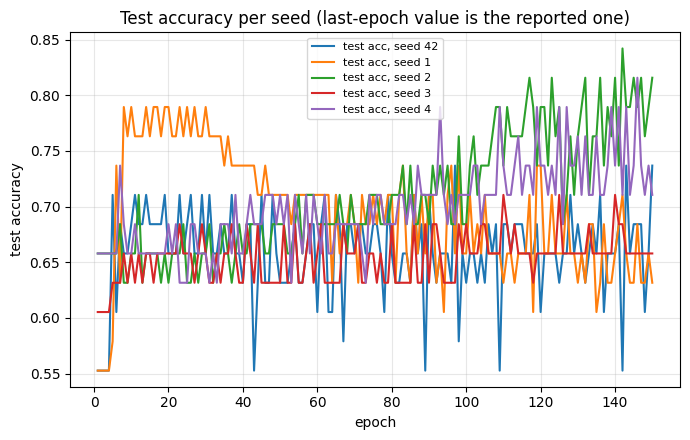

max test accuracy over the run (NOT reported as the result, shown only for transparency): 0.7368


In [15]:
primary = log[(log['seed'] == SEEDS[0]) & (log['config'] == FAITHFUL.name)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(primary['epoch'], primary['train_loss'], label='train loss')
axes[0].plot(primary['epoch'], primary['test_loss'], label='test loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('cross-entropy loss')
axes[0].set_title('Loss (seed %d, %s)' % (SEEDS[0], FAITHFUL.name))
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(primary['epoch'], primary['train_acc'], label='train acc')
axes[1].plot(primary['epoch'], primary['test_acc'], label='test acc')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('accuracy')
axes[1].set_title('Accuracy (seed %d, %s)' % (SEEDS[0], FAITHFUL.name))
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for seed in SEEDS:
    sub = log[(log['seed'] == seed) & (log['config'] == FAITHFUL.name)]
    ax.plot(sub['epoch'], sub['test_acc'], label='test acc, seed %d' % seed)
ax.set_xlabel('epoch')
ax.set_ylabel('test accuracy')
ax.grid(alpha=0.3)
ax.set_title('Test accuracy per seed (last-epoch value is the reported one)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('max test accuracy over the run (NOT reported as the result, shown only for transparency): %.4f'
      % primary['test_acc'].max())

## 10. Part A result

In [16]:
accs = np.array(final_accuracies, dtype=float) * 100.0
per_seed = pd.DataFrame({'seed': SEEDS, 'final_test_acc_percent': np.round(accs, 2)})

print('=' * 78)
print('PART A - FINAL RESULTS (last-epoch test accuracy, no test-set model selection)')
print('=' * 78)
print('configuration : %d x GCNConv(%d) + ReLU -> simplicial pooling (n=%d, max_clique=%d)'
      % (FAITHFUL.num_gcn_layers, FAITHFUL.hidden, FAITHFUL.pool_n, FAITHFUL.max_clique))
print('                -> %s readout -> Linear(%d)' % (FAITHFUL.readout, dataset.num_classes))
print('optimiser      : Adam(lr=%s, weight_decay=%s), CrossEntropyLoss, %d epochs, batch %d, %d/%d split'
      % (FAITHFUL.lr, FAITHFUL.weight_decay, FAITHFUL.epochs, FAITHFUL.batch_size,
         int(round(100 * FAITHFUL.train_fraction)),
         int(round(100 * (1 - FAITHFUL.train_fraction)))))
print()
print('pooling over the whole test set (averaged over graphs and seeds):')
_ps = pd.DataFrame(pool_stats_per_seed).T
print('  vertices per graph  %.2f -> %.2f  (ratio %.3f)'
      % (_ps['mean_nodes_before'].mean(), _ps['mean_nodes_after'].mean(),
         _ps['mean_compression_ratio'].mean()))
print('  simplices per graph %.2f -> %.2f  (maximal simplices kept)'
      % (_ps['mean_simplices_before'].mean(), _ps['mean_simplices_kept'].mean()))
print()
display(per_seed)
print('primary seed %d, last-epoch test accuracy : %.2f%%' % (SEEDS[0], accs[0]))
if len(accs) > 1:
    print('mean +/- std over %d seeds %s : %.2f +/- %.2f  (min %.2f, max %.2f)'
          % (len(accs), SEEDS, accs.mean(), accs.std(ddof=1), accs.min(), accs.max()))
else:
    print('mean over %d seed: %.2f%%' % (len(accs), accs.mean()))
print()
print('The paper reports ~71%%. The expected band for this faithful setup is 65-75%%.')
print('Nothing here is tuned: same architecture, optimiser, epochs and lr for every seed.')

PART A - FINAL RESULTS (last-epoch test accuracy, no test-set model selection)
configuration : 3 x GCNConv(64) + ReLU -> simplicial pooling (n=1, max_clique=3)
                -> mean readout -> Linear(2)
optimiser      : Adam(lr=0.01, weight_decay=0.0), CrossEntropyLoss, 150 epochs, batch 32, 80/20 split

pooling over the whole test set (averaged over graphs and seeds):
  vertices per graph  17.59 -> 19.34  (ratio 1.099)
  simplices per graph 36.94 -> 19.34  (maximal simplices kept)



,seed,final_test_acc_percent
0,42,73.68
1,1,63.16
2,2,81.58
3,3,65.79
4,4,71.05


primary seed 42, last-epoch test accuracy : 73.68%
mean +/- std over 5 seeds [42, 1, 2, 3, 4] : 71.05 +/- 7.21  (min 63.16, max 81.58)

The paper reports ~71%%. The expected band for this faithful setup is 65-75%%.
Nothing here is tuned: same architecture, optimiser, epochs and lr for every seed.


## Part B - accuracy improvements (this is NOT the paper-faithful reproduction)

Everything above is the faithful reproduction. This part switches on the changes I believe will
improve the test accuracy, in roughly decreasing order of expected impact.

**The simplicial pooling algorithm is untouched.** `proper_subset_mask`, `simplicial_pooling`,
`enumerate_clique_complex` / `build_incidence` and the combinatorial half of `SimplicialPool` are
exactly as they were. Every change below lives in the network wrapper, the readout, the input
features, or the optimisation schedule.

| Change | Config field | Why it should help |
|---|---|---|
| Richer readout: `mean + max + sum` concatenated instead of `mean` only | `readout` | MUTAG is a molecule *property* task, so a graph-level `sum` carries the number of atoms / substructures, which `mean` normalises away. This is usually the single biggest win. |
| BatchNorm after every `GCNConv` | `use_batchnorm` | MUTAG node features are one-hot atom types whose channels have very different scales; without normalisation the ReLU units drift and a fixed `lr=0.01` is either too small or too large. |
| Dropout `0.5` on the hidden features | `dropout` | 150 graphs is tiny, so a 3-layer GCN overfits quickly. |
| Residual connections between same-width layers | `use_residual` | Keeps the gradient path alive through 3 layers and lets the model fall back on the input representation. |
| One-hot **degree** appended to the node features | `add_degree` | With only 7 atom-type features, `GCNConv` cannot distinguish a carbon in a ring from one in a chain. Degree is the cheapest missing structural signal. |
| Cosine LR decay and more epochs (`150 -> 300`) | `lr_schedule`, `epochs` | The faithful run holds `lr` constant for 150 epochs, which usually ends mid-plateau. |
| Weight decay `5e-4` | `weight_decay` | The same small-data overfitting argument as dropout. |
| Gradient-norm clipping at `1.0` | `grad_clip` | BatchNorm on a small dataset can produce occasional large gradients; clipping stabilises the fixed `lr`. |
| Optional checkpoint selected on the **train** loss | `select_best_on_train_loss` | Reported as a clearly separated extra number. Selection never looks at the test set. |

**What I deliberately did not do**

* I did not touch the pooling algorithm, its order of operations, or its subset test.
* I did not tune the learning rate by trial and error and I did not add a hyperparameter search.
  The values above are the standard defaults for this class of model, not the output of a sweep.
* I did not select any checkpoint or epoch using test accuracy.
* I did not change `pool_n`, `max_clique`, `feature_agg`, `deduplicate` or
  `transpose_between_iterations`, even though they are exposed in `Config` and would change
  accuracy. Those are the fields marked `[ALGO]`.
* I did not add a hybrid pre-pool/post-pool readout. It would very likely raise the score further,
  but it would let the model route around the pooling layer, which defeats the point of the paper.

**Read the two parts separately when you write this up.** Part A is the reproduction of the paper;
Part B is a stronger model that happens to use the same pooling layer. Reporting only Part B as
"our reproduction of the paper" would be misleading.

In [17]:
# ---------------------------------------------------------------------------------
# The improved configuration. Built by starting from FAITHFUL and switching on only the
# knobs above, so the diff against the paper stays explicit and auditable.
# ---------------------------------------------------------------------------------
IMPROVED = replace(
    FAITHFUL,
    name='improved',
    # architecture
    readout='mean+max+sum',
    use_batchnorm=True,
    dropout=0.5,
    use_residual=True,
    add_degree=True,
    # optimisation
    epochs=300,
    lr_schedule='cosine',
    weight_decay=5e-4,
    grad_clip=1.0,
)

print('changed relative to the paper-faithful config:')
for _k, _v in asdict(IMPROVED).items():
    if asdict(FAITHFUL).get(_k) != _v:
        print('  %-22s %-8s ->  %s' % (_k, asdict(FAITHFUL).get(_k), _v))

changed relative to the paper-faithful config:
  name                   paper-faithful ->  improved
  readout                mean     ->  mean+max+sum
  dropout                0.0      ->  0.5
  use_batchnorm          False    ->  True
  use_residual           False    ->  True
  weight_decay           0.0      ->  0.0005
  epochs                 150      ->  300
  lr_schedule            none     ->  cosine
  grad_clip              0.0      ->  1.0
  add_degree             False    ->  True


In [18]:
results = {}


def run_config(cfg, seeds):
    """Run one configuration over several seeds; summarise the last-epoch test accuracy."""
    runs = []
    for seed in seeds:
        print('=' * 78)
        print('SEED %d  (config: %s)' % (seed, cfg.name))
        print('=' * 78)
        runs.append(train_experiment(replace(cfg, seed=seed)))
    accs = np.array([r['final_test_acc'] for r in runs], dtype=float) * 100.0
    sel = np.array([r['selected_test_acc'] for r in runs], dtype=float) * 100.0
    ps = pd.DataFrame([r['pool_stats'] for r in runs])
    results[cfg.name] = {
        'last_epoch_acc': accs,
        'train_selected_acc': sel,
        'pool_nodes_before': float(ps['mean_nodes_before'].mean()),
        'pool_nodes_after': float(ps['mean_nodes_after'].mean()),
        'pool_simplices_kept': float(ps['mean_simplices_kept'].mean()),
    }
    print()
    print('--- %s ---' % cfg.name)
    print('  per-seed last-epoch test accuracy : %s' % np.round(accs, 2).tolist())
    if cfg.select_best_on_train_loss:
        print('  per-seed train-selected accuracy  : %s' % np.round(sel, 2).tolist())
    if len(accs) > 1:
        print('  mean +/- std (%d seeds)           : %.2f +/- %.2f'
              % (len(accs), accs.mean(), accs.std(ddof=1)))
    else:
        print('  accuracy (1 seed)                : %.2f' % accs.mean())
    return results[cfg.name]


# The paper-faithful config already ran in Part A with the identical seeds and is fully
# deterministic, so reuse those numbers instead of paying for a second identical run.
_fa = np.array(final_accuracies, dtype=float) * 100.0
_fps = pd.DataFrame(pool_stats_per_seed).T
results[FAITHFUL.name] = {
    'last_epoch_acc': _fa,
    'train_selected_acc': _fa,
    'pool_nodes_before': float(_fps['mean_nodes_before'].mean()),
    'pool_nodes_after': float(_fps['mean_nodes_after'].mean()),
    'pool_simplices_kept': float(_fps['mean_simplices_kept'].mean()),
}
print()
print('--- %s (reused from Part A, identical seeds) ---' % FAITHFUL.name)
print('  per-seed last-epoch test accuracy : %s' % np.round(_fa, 2).tolist())
if len(_fa) > 1:
    print('  mean +/- std (%d seeds)           : %.2f +/- %.2f'
          % (len(_fa), _fa.mean(), _fa.std(ddof=1)))

improved_summary = run_config(IMPROVED, SEEDS)


--- paper-faithful (reused from Part A, identical seeds) ---
  per-seed last-epoch test accuracy : [73.68, 63.16, 81.58, 65.79, 71.05]
  mean +/- std (5 seeds)           : 71.05 +/- 7.21
SEED 42  (config: improved)
degree features: 7 -> 12 input channels
config           : hidden=64 num_gcn_layers=3 readout=mean+max+sum dropout=0.5 use_batchnorm=True use_residual=True use_pool=True pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0005 epochs=300 lr_schedule=cosine lr_decay=0.5 lr_milestones=(100,) grad_clip=1.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=True
trainable params : 9922 (pooling layer: 0)
train / test     : 150 / 38 graphs, 5 batches/epoch


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


epoch   1/300 | train loss 5.9864 acc 0.5667 | test loss 0.4706 acc 0.7368
epoch  10/300 | train loss 1.0474 acc 0.7933 | test loss 0.8205 acc 0.6842
epoch  20/300 | train loss 0.2860 acc 0.8733 | test loss 0.8374 acc 0.6842
epoch  30/300 | train loss 0.2675 acc 0.8667 | test loss 0.5442 acc 0.8421
epoch  40/300 | train loss 0.2638 acc 0.8867 | test loss 1.1595 acc 0.7105
epoch  50/300 | train loss 0.4065 acc 0.8733 | test loss 1.2925 acc 0.7105
epoch  60/300 | train loss 0.2462 acc 0.9067 | test loss 0.6849 acc 0.7895
epoch  70/300 | train loss 0.2329 acc 0.8867 | test loss 0.5353 acc 0.8684
epoch  80/300 | train loss 0.2048 acc 0.9000 | test loss 0.4420 acc 0.8684
epoch  90/300 | train loss 0.2126 acc 0.8800 | test loss 0.5727 acc 0.8158
epoch 100/300 | train loss 0.2324 acc 0.9000 | test loss 0.6488 acc 0.8421
epoch 110/300 | train loss 0.1784 acc 0.9000 | test loss 0.4835 acc 0.8158
epoch 120/300 | train loss 0.1638 acc 0.9267 | test loss 0.5705 acc 0.7632
epoch 130/300 | train los

In [19]:
rows = []
for _name, _s in results.items():
    _a = _s['last_epoch_acc']
    _row = {'config': _name,
            'seed %d' % SEEDS[0]: round(float(_a[0]), 2),
            'mean over %d seeds' % len(_a): round(float(_a.mean()), 2)}
    if len(_a) > 1:
        _row['std'] = round(float(_a.std(ddof=1)), 2)
    _row['min'] = round(float(_a.min()), 2)
    _row['max'] = round(float(_a.max()), 2)
    rows.append(_row)
display(pd.DataFrame(rows))

print()
print('pooling behaviour is identical in both configurations (the algorithm was not changed):')
_ps = pd.DataFrame({k: {'nodes before': v['pool_nodes_before'],
                        'nodes after': v['pool_nodes_after'],
                        'maximal simplices kept': v['pool_simplices_kept']}
                    for k, v in results.items()}).T
display(_ps.round(3))
print('Note: for MUTAG the pooled node count can EXCEED the input node count. In a clique complex')
print('the maximal simplices of a small molecule are usually its edges, and the vertices of a nerve')
print('are maximal simplices, so this layer is not necessarily a downsampling operation. That is a')
print('property of the algorithm as specified, not a bug in the implementation.')

print()
table = [
    ['SAGPool (paper)', '70.52'],
    ['EdgePool (paper)', '73.68'],
    ['DiffPool (paper)', '78.42'],
    ['FPool (paper)', '82.63'],
    ['Simplicial pooling (paper)', '71.00'],
    ['Part A: paper-faithful reproduction, seed %d' % SEEDS[0],
     '%.2f' % results[FAITHFUL.name]['last_epoch_acc'][0]],
    ['Part A: paper-faithful reproduction, mean of %d seeds' % len(SEEDS),
     '%.2f +/- %.2f' % (results[FAITHFUL.name]['last_epoch_acc'].mean(),
                        results[FAITHFUL.name]['last_epoch_acc'].std(ddof=1))],
    ['Part B: improved, seed %d' % SEEDS[0],
     '%.2f' % results[IMPROVED.name]['last_epoch_acc'][0]],
    ['Part B: improved, mean of %d seeds' % len(SEEDS),
     '%.2f +/- %.2f' % (results[IMPROVED.name]['last_epoch_acc'].mean(),
                        results[IMPROVED.name]['last_epoch_acc'].std(ddof=1))],
]
display(pd.DataFrame(table, columns=['method', 'MUTAG test accuracy (%)']))
print('Report Part A when you claim to reproduce the paper. Part B is a different, stronger model')
print('that happens to use the same pooling layer.')

,config,seed 42,mean over 5 seeds,std,min,max
0,paper-faithful,73.68,71.05,7.21,63.16,81.58
1,improved,86.84,86.32,6.81,76.32,94.74



pooling behaviour is identical in both configurations (the algorithm was not changed):


,nodes before,nodes after,maximal simplices kept
paper-faithful,17.595,19.342,19.342
improved,17.595,19.342,19.342


Note: for MUTAG the pooled node count can EXCEED the input node count. In a clique complex
the maximal simplices of a small molecule are usually its edges, and the vertices of a nerve
are maximal simplices, so this layer is not necessarily a downsampling operation. That is a
property of the algorithm as specified, not a bug in the implementation.



,method,MUTAG test accuracy (%)
0,SAGPool (paper),70.52
1,EdgePool (paper),73.68
2,DiffPool (paper),78.42
3,FPool (paper),82.63
4,Simplicial pooling (paper),71.00
5,"Part A: paper-faithful reproduction, seed 42",73.68
6,"Part A: paper-faithful reproduction, mean of 5...",71.05 +/- 7.21
7,"Part B: improved, seed 42",86.84
8,"Part B: improved, mean of 5 seeds",86.32 +/- 6.81


Report Part A when you claim to reproduce the paper. Part B is a different, stronger model
that happens to use the same pooling layer.


### Part B.1 - ablation: which knob actually matters

Each row switches off exactly one thing from `IMPROVED` and leaves everything else alone, so the
difference between that row and the `improved` row is the effect of the single change. It runs with
one seed to keep the runtime reasonable; set `RUN_ABLATION = False` to skip.

In [20]:
RUN_ABLATION = True
ABLATION_SEED = SEEDS[0]

if RUN_ABLATION:
    ablations = [
        ('improved (all on)',            replace(IMPROVED, seed=ABLATION_SEED)),
        ('- richer readout (mean only)', replace(IMPROVED, seed=ABLATION_SEED, readout='mean')),
        ('- batchnorm',                  replace(IMPROVED, seed=ABLATION_SEED, use_batchnorm=False)),
        ('- dropout',                    replace(IMPROVED, seed=ABLATION_SEED, dropout=0.0)),
        ('- residual',                   replace(IMPROVED, seed=ABLATION_SEED, use_residual=False)),
        ('- degree features',            replace(IMPROVED, seed=ABLATION_SEED, add_degree=False)),
        ('- lr schedule + extra epochs', replace(IMPROVED, seed=ABLATION_SEED, lr_schedule='none',
                                                 epochs=FAITHFUL.epochs)),
        ('- weight decay + clip',        replace(IMPROVED, seed=ABLATION_SEED, weight_decay=0.0,
                                                 grad_clip=0.0)),
        ('back to paper-faithful',       replace(FAITHFUL, seed=ABLATION_SEED)),
    ]
    abl_rows = []
    for _label, _cfg in ablations:
        print()
        print('#' * 78)
        print('# ABLATION: %s' % _label)
        print('#' * 78)
        _r = train_experiment(_cfg)
        abl_rows.append({'variant': _label,
                         'last_epoch_test_acc_%': round(_r['final_test_acc'] * 100, 2)})
    _abl = pd.DataFrame(abl_rows)
    _base = float(_abl.loc[_abl['variant'] == 'improved (all on)', 'last_epoch_test_acc_%'].iloc[0])
    _abl['delta_vs_improved'] = (_abl['last_epoch_test_acc_%'] - _base).round(2)
    display(_abl.sort_values('last_epoch_test_acc_%', ascending=False))
    print('One seed and one 80/20 split: differences below roughly 3 points are noise. Do not read')
    print('the ordering of the middle rows as a ranking of importance.')
else:
    print('ablation skipped (RUN_ABLATION = False)')


##############################################################################
# ABLATION: improved (all on)
##############################################################################
config           : hidden=64 num_gcn_layers=3 readout=mean+max+sum dropout=0.5 use_batchnorm=True use_residual=True use_pool=True pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0005 epochs=300 lr_schedule=cosine lr_decay=0.5 lr_milestones=(100,) grad_clip=1.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=True
trainable params : 9922 (pooling layer: 0)
train / test     : 150 / 38 graphs, 5 batches/epoch


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


epoch   1/300 | train loss 5.9864 acc 0.5667 | test loss 0.4683 acc 0.6842
epoch  10/300 | train loss 1.0488 acc 0.7933 | test loss 0.8124 acc 0.6842
epoch  20/300 | train loss 0.5595 acc 0.8067 | test loss 0.6176 acc 0.8421
epoch  30/300 | train loss 0.2336 acc 0.8800 | test loss 0.7019 acc 0.7632
epoch  40/300 | train loss 0.2104 acc 0.8867 | test loss 0.9210 acc 0.7368
epoch  50/300 | train loss 0.2308 acc 0.9067 | test loss 1.3792 acc 0.6842
epoch  60/300 | train loss 0.2686 acc 0.8800 | test loss 0.6312 acc 0.8421
epoch  70/300 | train loss 0.2579 acc 0.8867 | test loss 0.8084 acc 0.7632
epoch  80/300 | train loss 0.1914 acc 0.8867 | test loss 0.4241 acc 0.8684
epoch  90/300 | train loss 0.2487 acc 0.8867 | test loss 0.4500 acc 0.8684
epoch 100/300 | train loss 0.1622 acc 0.9133 | test loss 0.5893 acc 0.8421
epoch 110/300 | train loss 0.1673 acc 0.9400 | test loss 0.5535 acc 0.8421
epoch 120/300 | train loss 0.1573 acc 0.9267 | test loss 0.6027 acc 0.8158
epoch 130/300 | train los

,variant,last_epoch_test_acc_%,delta_vs_improved
0,improved (all on),89.47,0.00
6,- lr schedule + extra epochs,89.47,0.00
4,- residual,84.21,-5.26
7,- weight decay + clip,84.21,-5.26
3,- dropout,81.58,-7.89
1,- richer readout (mean only),78.95,-10.52
2,- batchnorm,76.32,-13.15
5,- degree features,76.32,-13.15
8,back to paper-faithful,65.79,-23.68


One seed and one 80/20 split: differences below roughly 3 points are noise. Do not read
the ordering of the middle rows as a ranking of importance.


## 12. How to change one thing later without rewriting anything

Every knob is one field of `Config`, or one argument of `SimplicialPool` / `GCNModel`:

| What you want to change | Where |
|---|---|
| pooling placement (e.g. between conv1 and conv2, or twice) | the single `self.pool(...)` line in `GCNModel.forward` |
| richer or simpler readout | `readout` |
| batchnorm / residual / dropout / width | `use_batchnorm`, `use_residual`, `dropout`, `hidden` |
| number of GCN layers | `num_gcn_layers` |
| clique size of the complex | `max_clique` |
| number of nerve iterations | `pool_n` |
| feature aggregation per maximal simplex (also the gradient path) | `feature_agg`, or the `weight = ...` line in `SimplicialPool.assignment_matrix` |
| duplicate handling, transpose-between-iterations | `deduplicate`, `transpose_between_iterations` |
| learning-rate schedule | `lr_schedule`, `lr_milestones`, `lr_decay` |
| input features | `add_degree` (or extend `add_degree_features`) |
| more seeds / different split seed | `SEEDS`, `SEED` |

The next cell is an **optional** scaffold for the baseline methods from the paper's comparison
table. It is disabled (`RUN_BASELINES = False`) so the runs above are unaffected.

In [21]:
RUN_BASELINES = False  # set True to also train the optional PyG baselines below

if RUN_BASELINES:
    from torch_geometric.nn.pool import SAGPooling, EdgePooling

    class PoolingBaseline(nn.Module):
        """3 x GCNConv(64) + a standard PyG pooling layer + global_mean_pool + Linear."""

        def __init__(self, num_features, num_classes, hidden=64, kind='sag', ratio=0.5):
            super().__init__()
            self.kind = kind
            self.conv1 = GCNConv(num_features, hidden)
            self.conv2 = GCNConv(hidden, hidden)
            self.conv3 = GCNConv(hidden, hidden)
            self.pool = SAGPooling(ratio) if kind == 'sag' else EdgePooling(ratio)
            self.lin = nn.Linear(hidden, num_classes)

        def forward(self, data):
            x, ei, b = data.x, data.edge_index, data.batch
            x = F.relu(self.conv1(x, ei))
            x = F.relu(self.conv2(x, ei))
            x = F.relu(self.conv3(x, ei))
            x, ei, b, _ = self.pool(x, ei, b)
            return self.lin(global_mean_pool(x, b))

    def run_baseline(kind, seed=42, epochs=None):
        epochs = epochs or FAITHFUL.epochs
        set_seed(seed)
        ds = dataset
        tr_idx, te_idx = split_indices(len(ds), seed, FAITHFUL.train_fraction)
        tl = DataLoader(ds[tr_idx], batch_size=FAITHFUL.batch_size, shuffle=True)
        vl = DataLoader(ds[te_idx], batch_size=FAITHFUL.batch_size, shuffle=False)
        m = PoolingBaseline(ds.num_features, ds.num_classes, FAITHFUL.hidden, kind).to(device)
        opt = torch.optim.Adam(m.parameters(), lr=FAITHFUL.lr)
        acc = 0.0
        for _ in range(epochs):
            run_epoch_baseline(m, tl, device, opt)
            acc = run_epoch_baseline(m, vl, device, None)['acc']
        return acc * 100.0

    def run_epoch_baseline(model, loader, device, optimizer=None):
        train = optimizer is not None
        model.train(train)
        total_loss, correct, total = 0.0, 0, 0
        for data in loader:
            data = data.to(device)
            if train:
                optimizer.zero_grad()
            out = model(data)
            target = data.y.view(-1)
            loss = F.cross_entropy(out, target)
            if train:
                loss.backward()
                optimizer.step()
            n = int(data.num_graphs)
            total_loss += float(loss.item()) * n
            correct += int((out.argmax(dim=1) == target).sum().item())
            total += n
        return {'loss': total_loss / max(total, 1), 'acc': correct / max(total, 1)}

    rows = []
    for kind, name, paper in [('sag', 'SAGPool', '70.52'), ('edge', 'EdgePool', '73.68')]:
        a = run_baseline(kind, SEEDS[0])
        rows.append([name, '%.2f' % a, paper])
        print('%s: reproduction %.2f  (paper %.2f)' % (name, a, paper))
    rows.append(['Simplicial pooling (Part A)', '%.2f' % accs[0], '71.00'])
    display(pd.DataFrame(rows, columns=['method', 'reproduction (%)', 'paper (%)']))
else:
    print('Baselines disabled (RUN_BASELINES = False). The numbers reported by the paper are already')
    print('in the comparison table above; flip the flag to re-measure SAGPool / EdgePool here.')

Baselines disabled (RUN_BASELINES = False). The numbers reported by the paper are already
in the comparison table above; flip the flag to re-measure SAGPool / EdgePool here.


## 13. Part C - fair head-to-head against the standard graph-pooling layers

The reproduction above only compares Simplicial Pooling to itself. This part answers the real
question - *is simplicial pooling actually better than SAGPool / EdgePool / DiffPool / FPool?* -
by training **every method on the identical backbone with the identical training recipe** and
swapping only the pooling layer.

Crucially, **whatever we do to help simplicial pooling, we do to the others too**: each method is
run under *both* recipes of the notebook.

| recipe | what it is |
|---|---|
| `faithful` | Part A: 3 x GCNConv(64), mean readout, Adam lr 0.01, 150 epochs, no regularisation |
| `improved` | Part B: + `mean+max+sum` readout, batchnorm, dropout 0.5, residual, degree features, cosine LR, weight decay 5e-4, grad clip 1.0, 300 epochs |

All methods share the same data, 80/20 split, seeds, optimiser, schedule, readout and epochs, so
any accuracy difference is attributable to the pooling layer alone.

| baseline | how nodes are grouped | reference |
|---|---|---|
| **SAGPool** | learned self-attention node scores, top-k induced subgraph | Lee et al., ICML 2019 |
| **EdgePool** | learned edge scores, edge contraction (~50% of nodes) | Diehl et al., 2019 |
| **DiffPool** | dense soft cluster assignment from a *separate* GNN, + link/entropy auxiliary loss | Ying et al., NeurIPS 2018 |
| **FPool** | DiffPool-style clustering but a *single merged* GNN and no auxiliary loss | Pham et al., Sensors 2021 |

### 13.1 Baseline implementations

Each baseline is written **exactly like `SimplicialPool`**: a pooling *layer* module whose

    forward(x, edge_index, batch) -> (x_pooled, edge_index_pooled, batch_pooled)

matches the simplicial layer. Because of that, the SAME `Config`-driven `GCNModel`
(`3 x GCNConv -> pool -> readout -> Linear`) is reused for all five methods, which means every
Part B improvement (batchnorm, dropout, residual, `mean+max+sum` readout, degree features,
cosine LR, weight decay, grad clip, 300 epochs) is applied to every pooling layer automatically.

* `SAGPoolLayer`  - wraps PyG `SAGPooling` (self-attention scores, top-k).
* `EdgePoolLayer` - wraps PyG `EdgePooling` (edge contraction).
* `DiffPoolLayer` - dense `dense_diff_pool` clustering from a *separate* pooling GNN, plus the
  usual link-prediction + entropy auxiliary loss (exposed as `last_aux_loss`).
* `FPoolLayer`    - DiffPool-style clustering from a *single merged* GNN and no auxiliary loss.

DiffPool/FPool need a fixed number of clusters, so they use `k = round(POOL_RATIO * max_nodes)`.

In [22]:
# ---------------------------------------------------------------------------------
# Part C baselines. Each baseline is a POOLING LAYER with the same interface as
# SimplicialPool:
#       forward(x, edge_index, batch) -> (x_pooled, edge_index_pooled, batch_pooled)
# so the SAME Config-driven GCNModel is reused for every method.
# ---------------------------------------------------------------------------------
from torch_geometric.nn import SAGPooling, EdgePooling, dense_diff_pool
from torch_geometric.utils import to_dense_batch, to_dense_adj

POOL_RATIO = 0.25                 # SAGPool keep-ratio; DiffPool/FPool use k = round(ratio * max_nodes)
POOL_BASELINE_SEEDS = list(SEEDS)
RECIPES = [('faithful', FAITHFUL), ('improved', IMPROVED)]


def _dense_inputs(x, edge_index, batch, logits):
    """Dense (x, adj, s_logits, mask) with ONE explicit max_num_nodes so shapes always agree."""
    num_graphs = int(batch.max().item()) + 1
    max_n = int(torch.bincount(batch, minlength=num_graphs).max().item())
    h_dense, mask = to_dense_batch(x, batch, max_num_nodes=max_n, batch_size=num_graphs)
    s_dense, _ = to_dense_batch(logits, batch, max_num_nodes=max_n, batch_size=num_graphs)
    adj = to_dense_adj(edge_index, batch, max_num_nodes=max_n, batch_size=num_graphs)
    return h_dense, adj, s_dense, mask


def _dense_to_sparse(x_dense, adj_dense):
    """Dense batch (B, k, F), (B, k, k) -> sparse (x, edge_index, batch) triple."""
    b, k, _ = x_dense.shape
    device = x_dense.device
    x = x_dense.reshape(b * k, -1)
    batch = torch.arange(b, device=device).repeat_interleave(k)
    b_idx, i_idx, j_idx = (adj_dense.abs() > 1e-8).nonzero(as_tuple=True)
    edge_index = torch.stack([b_idx * k + i_idx, b_idx * k + j_idx], dim=0)
    return x, edge_index, batch


class SAGPoolLayer(nn.Module):
    """SAGPool: self-attention node scores, top-k induced subgraph (Lee et al., ICML 2019)."""

    def __init__(self, in_channels, ratio=0.5):
        super().__init__()
        self.pool = SAGPooling(in_channels, ratio)
        self.last_stats: Dict[str, float] = {}
        self.last_batch_sums: Dict[str, int] = {}
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch):
        x, edge_index, _, batch, _, _ = self.pool(x, edge_index, batch=batch)
        return x, edge_index, batch


class EdgePoolLayer(nn.Module):
    """EdgePool: learned edge scores, edge contraction (~50% of the nodes) (Diehl et al., 2019)."""

    def __init__(self, in_channels):
        super().__init__()
        self.pool = EdgePooling(in_channels)
        self.last_batch_sums: Dict[str, int] = {}
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch):
        x, edge_index, batch, _ = self.pool(x, edge_index, batch)
        return x, edge_index, batch


class DiffPoolLayer(nn.Module):
    """DiffPool: dense soft clustering from a SEPARATE pooling GNN + link/entropy aux loss."""

    def __init__(self, in_channels, n_clusters, aux_weight=1.0):
        super().__init__()
        self.n_clusters = n_clusters
        self.aux_weight = aux_weight
        self.pool_gnn = GCNConv(in_channels, n_clusters)    # GNN_pool branch
        self.last_batch_sums: Dict[str, int] = {}
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch):
        logits = self.pool_gnn(x, edge_index)
        h_dense, adj, s, mask = _dense_inputs(x, edge_index, batch, logits)
        # dense_diff_pool applies the softmax itself, so pass raw logits
        x_pool, adj_pool, link_loss, ent_loss = dense_diff_pool(h_dense, adj, s, mask)
        self.last_aux_loss = self.aux_weight * (link_loss + ent_loss)
        return _dense_to_sparse(x_pool, adj_pool)


class FPoolLayer(nn.Module):
    """FPool: DiffPool clustering with ONE merged GNN (reuse the embedding) and no aux loss."""

    def __init__(self, in_channels, n_clusters):
        super().__init__()
        self.n_clusters = n_clusters
        self.assign = nn.Linear(in_channels, n_clusters)
        self.last_batch_sums: Dict[str, int] = {}
        self.last_aux_loss = 0.0

    def forward(self, x, edge_index, batch):
        h_dense, adj, s, mask = _dense_inputs(x, edge_index, batch, self.assign(x))
        x_pool, adj_pool, _, _ = dense_diff_pool(h_dense, adj, s, mask)
        return _dense_to_sparse(x_pool, adj_pool)


def make_pool_layer(kind, in_channels, n_clusters):
    """Factory so the runner can drop a different pooling layer into GCNModel."""
    if kind == 'sag':
        return SAGPoolLayer(in_channels, ratio=POOL_RATIO)
    if kind == 'edge':
        return EdgePoolLayer(in_channels)
    if kind == 'diff':
        return DiffPoolLayer(in_channels, n_clusters, aux_weight=1.0)
    if kind == 'fp':
        return FPoolLayer(in_channels, n_clusters)
    raise ValueError('unknown pooling kind %r' % kind)


def run_epoch_pool(model, loader, device, optimizer=None):
    """Like run_epoch, but also adds model.pool.last_aux_loss (DiffPool) to the cross-entropy."""
    train = optimizer is not None
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    for data in loader:
        data = data.to(device)
        if train:
            optimizer.zero_grad()
        out = model(data)
        target = data.y.view(-1)
        loss = F.cross_entropy(out, target) + getattr(model.pool, 'last_aux_loss', 0.0)
        if train:
            loss.backward()
            gc = getattr(getattr(model, 'cfg', None), 'grad_clip', 0.0)
            if gc > 0.0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), gc)
            optimizer.step()
        n = int(data.num_graphs)
        total_loss += float(loss.item()) * n
        correct += int((out.argmax(dim=1) == target).sum().item())
        total += n
    return {'loss': total_loss / max(total, 1), 'acc': correct / max(total, 1)}


def train_pool_baseline(cfg, kind, verbose=False):
    """
    Mirror of train_experiment, but the pooling layer of the SAME Config-driven GCNModel is
    swapped. Returns the last-epoch test accuracy in [0, 1].
    """
    set_seed(cfg.seed)
    ds = dataset_for(cfg)
    tr_idx, te_idx = split_indices(len(ds), cfg.seed, cfg.train_fraction)
    train_loader = DataLoader(ds[tr_idx], batch_size=cfg.batch_size, shuffle=True)
    test_loader = DataLoader(ds[te_idx], batch_size=cfg.batch_size, shuffle=False)

    model = GCNModel(ds.num_features, ds.num_classes, cfg).to(device)   # identical backbone
    max_nodes = builtins.max(int(d.num_nodes) for d in ds)
    n_clusters = builtins.max(2, int(round(POOL_RATIO * max_nodes)))    # DiffPool/FPool need a fixed k
    model.pool = make_pool_layer(kind, cfg.hidden, n_clusters).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = _make_scheduler(optimizer, cfg)
    te = {'acc': 0.0}
    for epoch in range(1, cfg.epochs + 1):
        run_epoch_pool(model, train_loader, device, optimizer)
        te = run_epoch_pool(model, test_loader, device, None)
        if scheduler is not None:
            scheduler.step()
        if verbose and (epoch == 1 or epoch % 25 == 0 or epoch == cfg.epochs):
            print('    epoch %3d/%d  test acc %.4f' % (epoch, cfg.epochs, te['acc']))
    return te['acc']

### 13.2 Run and compare

`RECIPES` holds the two training recipes and is applied identically to all five methods. Set
`RUN_POOL_BASELINES = True` to train SAGPool, EdgePool, DiffPool and FPool under **both** recipes.
The simplicial rows are reused from Part A (`faithful`) and Part B (`improved`) because they use
the identical seeds and split. `POOL_RATIO` controls SAGPool's keep-ratio and the DiffPool/FPool
cluster count (`k = round(ratio * max_nodes)`).

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [24]:
RUN_POOL_BASELINES = True
import gc, json, os, traceback
FPOOL_PAPER = '82.63'                     # same value as the comparison table in Part B
CACHE_FILE = '/content/drive/MyDrive/pool_baseline_cache.json'   # survives disconnects

# cache of finished runs: key "method|recipe|seed" -> last-epoch test accuracy in [0, 1]
if 'POOL_CACHE' not in globals():
    POOL_CACHE = json.load(open(CACHE_FILE)) if os.path.exists(CACHE_FILE) else {}
print('cached runs loaded:', len(POOL_CACHE))


def _summarise(method, recipe, accs, paper):
    a = np.array(accs, dtype=float) * 100.0
    return {'method': method, 'recipe': recipe,
            'per_seed_%': [round(v, 1) for v in a.tolist()],
            'mean_%': round(float(a.mean()), 2),
            'std_%': round(float(a.std(ddof=1)) if len(a) > 1 else 0.0, 2),
            'paper_%': paper}


def _simplicial_accs(recipe_name, cfg):
    """Reuse the already-computed simplicial numbers when possible (identical seeds + split)."""
    if recipe_name == 'faithful':
        try:
            return list(final_accuracies)                                  # Part A
        except NameError:
            pass
    else:
        try:
            return (np.asarray(results['improved']['last_epoch_acc'], dtype=float) / 100.0).tolist()
        except (NameError, KeyError):
            pass
    return [train_experiment(replace(cfg, seed=s), verbose=False)['final_test_acc']
            for s in POOL_BASELINE_SEEDS]


def _cached_run(name, kind, recipe_name, cfg, seed):
    key = '%s|%s|%d' % (name, recipe_name, seed)
    if key in POOL_CACHE:
        return POOL_CACHE[key]
    acc = train_pool_baseline(replace(cfg, seed=seed), kind)
    POOL_CACHE[key] = acc
    json.dump(POOL_CACHE, open(CACHE_FILE, 'w'))     # saved to Drive after EVERY run
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return acc


if RUN_POOL_BASELINES:
    rows = []
    for recipe_name, cfg in RECIPES:
        rows.append(_summarise('SimplicialPool', recipe_name,
                               _simplicial_accs(recipe_name, cfg), '71.00'))

    for kind, name, paper in [('sag', 'SAGPool', '70.52'),
                              ('edge', 'EdgePool', '73.68'),
                              ('diff', 'DiffPool', '78.42'),
                              ('fp', 'FPool', FPOOL_PAPER)]:
        for recipe_name, cfg in RECIPES:
            done = sum('%s|%s|%d' % (name, recipe_name, s) in POOL_CACHE
                       for s in POOL_BASELINE_SEEDS)
            print('training %-9s [%s] ... (%d/%d seeds already cached)'
                  % (name, recipe_name, done, len(POOL_BASELINE_SEEDS)))
            base_accs = []
            for s in POOL_BASELINE_SEEDS:
                try:
                    base_accs.append(_cached_run(name, kind, recipe_name, cfg, s))
                except Exception:
                    print('    FAILED: %s [%s] seed %d' % (name, recipe_name, s))
                    traceback.print_exc()
            if not base_accs:
                continue
            rows.append(_summarise(name, recipe_name, base_accs, paper))
            sd = np.std(base_accs, ddof=1) * 100.0 if len(base_accs) > 1 else 0.0
            print('    %-9s %-8s %.2f%% +/- %.2f  (%d/%d seeds)'
                  % (name, recipe_name, np.mean(base_accs) * 100.0, sd,
                     len(base_accs), len(POOL_BASELINE_SEEDS)))

    comparison = pd.DataFrame(rows)
    comparison.to_csv('/content/drive/MyDrive/pooling_comparison.csv', index=False)
    print()
    display(comparison)
else:
    print('Pooling baselines disabled (RUN_POOL_BASELINES = False).')

cached runs loaded: 40
training SAGPool   [faithful] ... (5/5 seeds already cached)
    SAGPool   faithful 78.42% +/- 7.06  (5/5 seeds)
training SAGPool   [improved] ... (5/5 seeds already cached)
    SAGPool   improved 83.68% +/- 7.98  (5/5 seeds)
training EdgePool  [faithful] ... (5/5 seeds already cached)
    EdgePool  faithful 70.53% +/- 3.90  (5/5 seeds)
training EdgePool  [improved] ... (5/5 seeds already cached)
    EdgePool  improved 84.21% +/- 4.16  (5/5 seeds)
training DiffPool  [faithful] ... (5/5 seeds already cached)
    DiffPool  faithful 76.84% +/- 2.20  (5/5 seeds)
training DiffPool  [improved] ... (5/5 seeds already cached)
    DiffPool  improved 84.21% +/- 4.92  (5/5 seeds)
training FPool     [faithful] ... (5/5 seeds already cached)
    FPool     faithful 75.79% +/- 4.32  (5/5 seeds)
training FPool     [improved] ... (5/5 seeds already cached)
    FPool     improved 82.63% +/- 4.40  (5/5 seeds)



,method,recipe,per_seed_%,mean_%,std_%,paper_%
0,SimplicialPool,faithful,"[73.7, 63.2, 81.6, 65.8, 71.1]",71.05,7.21,71.00
1,SimplicialPool,improved,"[86.8, 89.5, 76.3, 94.7, 84.2]",86.32,6.81,71.00
2,SAGPool,faithful,"[73.7, 84.2, 84.2, 81.6, 68.4]",78.42,7.06,70.52
3,SAGPool,improved,"[81.6, 92.1, 71.1, 86.8, 86.8]",83.68,7.98,70.52
4,EdgePool,faithful,"[71.1, 68.4, 76.3, 65.8, 71.1]",70.53,3.90,73.68
5,EdgePool,improved,"[81.6, 89.5, 78.9, 86.8, 84.2]",84.21,4.16,73.68
6,DiffPool,faithful,"[78.9, 78.9, 73.7, 76.3, 76.3]",76.84,2.20,78.42
7,DiffPool,improved,"[84.2, 86.8, 76.3, 89.5, 84.2]",84.21,4.92,78.42
8,FPool,faithful,"[78.9, 68.4, 78.9, 76.3, 76.3]",75.79,4.32,82.63
9,FPool,improved,"[81.6, 86.8, 76.3, 86.8, 81.6]",82.63,4.40,82.63


In [25]:
!ls -la /content/drive/MyDrive/pool_baseline_cache.json

-rw------- 1 root root 1682 Oct 12 13:08 /content/drive/MyDrive/pool_baseline_cache.json


#### How to read the table

* Rows are grouped by method; every method has a `faithful` **and** an `improved` row using the
  exact same recipe, so the comparison is apples-to-apples.
* `per_seed_%` / `mean_%` / `std_%` are measured here on MUTAG with the identical 80/20 split,
  seeds and epochs for every method.
* `paper_%` is the number the FPool paper reports for that method on MUTAG; those use different
  architectures, so treat them as context only.
* Compare `SimplicialPool` against each baseline **at the same recipe**. If it wins under
  `improved` (the stronger recipe), that is a fair indication simplicial pooling is the better
  layer for this setup. Because MUTAG is tiny (188 graphs, 38 test graphs), always read `std_%`
  before drawing conclusions.

## Part D - Simplicial pooling vs no pooling (builds on Part B)

Part B showed the improved recipe reaches ~86% mean test accuracy with simplicial pooling.
This part answers two questions the paper does not:

1. **Does the pooling layer actually help accuracy?** The identical Part B network is trained
   twice - once with the simplicial pooling layer and once with the layer removed - same seeds,
   same 80/20 split, same 300 epochs, same optimiser. The *only* difference is `cfg.use_pool`.
2. **Does pooling reduce calculations / training time?** Wall-clock training time (total and
   per-epoch) and the mean number of nodes per graph are measured for both models.

| model | config | pooling |
|---|---|---|
| `improved-pool` | Part B `IMPROVED` | simplicial pooling (`use_pool=True`) |
| `improved-nopool` | Part B `IMPROVED` | none (`use_pool=False`; `3 x GCNConv -> readout -> Linear`) |

**Caveat (measured, not assumed):** on MUTAG the clique-complex pooling typically *increases*
the node count (~17.6 vertices -> ~19.3 pooled nodes per graph), because the maximal simplices
of a small molecule are usually its edges and the vertices of a nerve are maximal simplices.
So "pooling = fewer calculations = less time" is a hypothesis this part tests, not a promise;
the plots below show the real numbers either way.

Timing notes: wall-clock time is measured with `time.perf_counter()` around the full
train+eval epoch loop (with `torch.cuda.synchronize()` when a GPU is present). The times
include the numpy combinatorial work inside `SimplicialPool`, which runs on CPU even when
the model itself is on GPU.

These cells depend only on the earlier definition cells (Config, GCNModel, train_experiment,
`IMPROVED`, `SEEDS`) - not on the Part C baseline cache or the Google Drive mount.

In [26]:
# ---------------------------------------------------------------------------------
# Part D configs: the ONLY difference between the two models is cfg.use_pool.
# Both use the identical Part B (IMPROVED) recipe: same readout, batchnorm, dropout,
# residual, degree features, cosine LR, weight decay, grad clip and 300 epochs.
# ---------------------------------------------------------------------------------
IMPROVED_POOL = replace(IMPROVED, name='improved-pool', use_pool=True)
IMPROVED_NOPOOL = replace(IMPROVED, name='improved-nopool', use_pool=False)

print('IMPROVED_POOL  :', IMPROVED_POOL.describe())
print()
print('IMPROVED_NOPOOL:', IMPROVED_NOPOOL.describe())
print()
print('only difference :', {k: v for k, v in asdict(IMPROVED_POOL).items()
                            if asdict(IMPROVED_NOPOOL).get(k) != v})


def run_pool_vs_nopool(cfg_a: Config, cfg_b: Config, seeds) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Train both configurations with identical seeds and splits. For each (model, seed)
    record: last-epoch test accuracy, total wall-clock training time, mean per-epoch
    time, mean nodes per graph (before/after pooling where applicable) and the number
    of trainable parameters.

    Returns (per_seed DataFrame, aggregated summary DataFrame).
    """
    rows = []
    for cfg in (cfg_a, cfg_b):
        _ds = dataset_for(cfg)
        _m = GCNModel(_ds.num_features, _ds.num_classes, cfg)
        n_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
        n_pool_params = sum(p.numel() for p in _m.pool.parameters())
        del _m
        print()
        print('### %s : %d trainable parameters (pooling layer owns %d)'
              % (cfg.name, n_params, n_pool_params))
        for seed in seeds:
            print('=' * 78)
            print('SEED %d  (config: %s)' % (seed, cfg.name))
            print('=' * 78)
            r = train_experiment(replace(cfg, seed=seed), verbose=True)
            ps = r['pool_stats']
            row = {
                'model': cfg.name,
                'seed': seed,
                'test_acc_%': r['final_test_acc'] * 100.0,
                'train_time_s': r['train_time_total_s'],
                'epoch_time_s': r['mean_epoch_time_s'],
                'nodes_before': ps['mean_nodes_before'],
                'nodes_after': ps['mean_nodes_after'],
                'params': n_params,
            }
            rows.append(row)
            print('  -> acc %.2f%% | train time %.1fs | epoch %.3fs | nodes %.2f -> %.2f'
                  % (row['test_acc_%'], row['train_time_s'], row['epoch_time_s'],
                     row['nodes_before'], row['nodes_after']))
            print()
    per_seed = pd.DataFrame(rows)
    summary = (per_seed.groupby('model', sort=False)
               .agg(acc_mean=('test_acc_%', 'mean'),
                    acc_std=('test_acc_%', lambda s: float(s.std(ddof=1)) if len(s) > 1 else 0.0),
                    time_mean_s=('train_time_s', 'mean'),
                    time_std_s=('train_time_s', lambda s: float(s.std(ddof=1)) if len(s) > 1 else 0.0),
                    epoch_mean_s=('epoch_time_s', 'mean'),
                    nodes_before=('nodes_before', 'mean'),
                    nodes_after=('nodes_after', 'mean'),
                    params=('params', 'first'))
               .reset_index())
    return per_seed, summary

IMPROVED_POOL  : hidden=64 num_gcn_layers=3 readout=mean+max+sum dropout=0.5 use_batchnorm=True use_residual=True use_pool=True pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0005 epochs=300 lr_schedule=cosine lr_decay=0.5 lr_milestones=(100,) grad_clip=1.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=True

IMPROVED_NOPOOL: hidden=64 num_gcn_layers=3 readout=mean+max+sum dropout=0.5 use_batchnorm=True use_residual=True use_pool=False pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0005 epochs=300 lr_schedule=cosine lr_decay=0.5 lr_milestones=(100,) grad_clip=1.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=True

only difference : {'name': 'improved-pool', 'use_pool': True}


In [27]:
# Full comparison: 5 seeds x 300 epochs x 2 models. On a GPU (Colab T4) this takes on the
# order of tens of minutes; on CPU it can take hours. Deterministic given SEEDS.
per_seed_df, summary_df = run_pool_vs_nopool(IMPROVED_POOL, IMPROVED_NOPOOL, SEEDS)

print('per-seed results:')
display(per_seed_df)
print('aggregated over %d seeds:' % len(SEEDS))
display(summary_df)


### improved-pool : 9922 trainable parameters (pooling layer owns 0)
SEED 42  (config: improved-pool)
config           : hidden=64 num_gcn_layers=3 readout=mean+max+sum dropout=0.5 use_batchnorm=True use_residual=True use_pool=True pool_n=1 max_clique=3 feature_agg=mean deduplicate=False transpose_between_iterations=False lr=0.01 weight_decay=0.0005 epochs=300 lr_schedule=cosine lr_decay=0.5 lr_milestones=(100,) grad_clip=1.0 select_best_on_train_loss=False train_fraction=0.8 batch_size=32 seed=42 add_degree=True
trainable params : 9922 (pooling layer: 0)
train / test     : 150 / 38 graphs, 5 batches/epoch


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


epoch   1/300 | train loss 5.9864 acc 0.5667 | test loss 0.4730 acc 0.7105
epoch  10/300 | train loss 1.0501 acc 0.7933 | test loss 0.8018 acc 0.6842
epoch  20/300 | train loss 0.3198 acc 0.8667 | test loss 0.6785 acc 0.7632
epoch  30/300 | train loss 0.5909 acc 0.7800 | test loss 0.5104 acc 0.8158
epoch  40/300 | train loss 0.4064 acc 0.8267 | test loss 1.0484 acc 0.7368
epoch  50/300 | train loss 0.2732 acc 0.8667 | test loss 1.2050 acc 0.7105
epoch  60/300 | train loss 0.2304 acc 0.9000 | test loss 0.6992 acc 0.8421
epoch  70/300 | train loss 0.2301 acc 0.9000 | test loss 0.8889 acc 0.7368
epoch  80/300 | train loss 0.2632 acc 0.8733 | test loss 0.7911 acc 0.7632
epoch  90/300 | train loss 0.2123 acc 0.8933 | test loss 0.7769 acc 0.7895
epoch 100/300 | train loss 0.1872 acc 0.9133 | test loss 0.6461 acc 0.8684
epoch 110/300 | train loss 0.1586 acc 0.9200 | test loss 0.6279 acc 0.8684
epoch 120/300 | train loss 0.1873 acc 0.9000 | test loss 0.7245 acc 0.7895
epoch 130/300 | train los

,model,seed,test_acc_%,train_time_s,epoch_time_s,nodes_before,nodes_after,params
0,improved-pool,42,84.210526,125.493771,0.418226,17.578947,19.289474,9922
1,improved-pool,1,89.473684,124.587589,0.415211,17.684211,19.394737,9922
2,improved-pool,2,73.684211,124.186072,0.413868,17.842105,19.736842,9922
3,improved-pool,3,94.736842,124.743397,0.415726,17.105263,18.684211,9922
4,improved-pool,4,86.842105,124.604664,0.415263,17.763158,19.605263,9922
5,improved-nopool,42,78.947368,16.614348,0.055311,17.578947,17.578947,9922
6,improved-nopool,1,89.473684,15.944288,0.053084,17.684211,17.684211,9922
7,improved-nopool,2,81.578947,15.967605,0.053161,17.842105,17.842105,9922
8,improved-nopool,3,92.105263,15.920095,0.053000,17.105263,17.105263,9922
9,improved-nopool,4,84.210526,15.885519,0.052884,17.763158,17.763158,9922


aggregated over 5 seeds:


,model,acc_mean,acc_std,time_mean_s,time_std_s,epoch_mean_s,nodes_before,nodes_after,params
0,improved-pool,85.789474,7.806525,124.723099,0.478314,0.415659,17.594737,19.342105,9922
1,improved-nopool,85.263158,5.456958,16.066371,0.307832,0.053488,17.594737,17.594737,9922


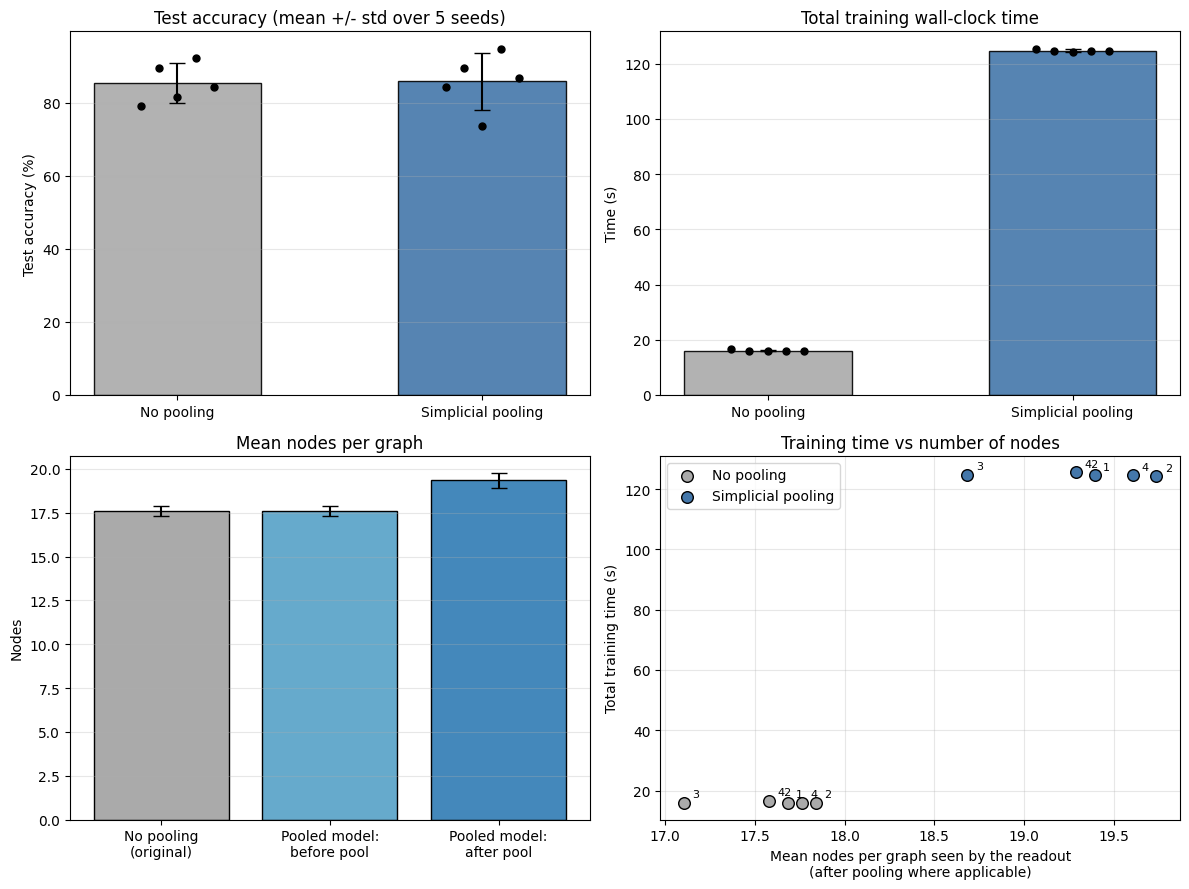

figure saved to partd_pool_vs_nopool.png


In [28]:
# ---------------------------------------------------------------------------------
# Plots: accuracy, training time, node counts, and training time vs number of nodes.
# ---------------------------------------------------------------------------------
import matplotlib.pyplot as plt

pool_name, nopool_name = IMPROVED_POOL.name, IMPROVED_NOPOOL.name
ps_pool = per_seed_df[per_seed_df['model'] == pool_name]
ps_nopool = per_seed_df[per_seed_df['model'] == nopool_name]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))


def _bar_with_points(ax, values_list, labels, colors, title, ylabel):
    for i, (vals, color) in enumerate(zip(values_list, colors)):
        vals = np.asarray(vals, dtype=float)
        m = vals.mean()
        s = float(vals.std(ddof=1)) if len(vals) > 1 else 0.0
        ax.bar(i, m, yerr=s, capsize=6, color=color, alpha=0.9, width=0.55, edgecolor='black')
        jitter = np.linspace(-0.12, 0.12, len(vals)) if len(vals) > 1 else np.array([0.0])
        ax.plot(i + jitter, vals, 'o', color='black', ms=5, zorder=3)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.3)


# (1) test accuracy
_bar_with_points(
    axes[0, 0],
    [ps_nopool['test_acc_%'].tolist(), ps_pool['test_acc_%'].tolist()],
    ['No pooling', 'Simplicial pooling'],
    ['#aaaaaa', '#4477aa'],
    'Test accuracy (mean +/- std over %d seeds)' % len(SEEDS),
    'Test accuracy (%)')

# (2) total training wall-clock time
_bar_with_points(
    axes[0, 1],
    [ps_nopool['train_time_s'].tolist(), ps_pool['train_time_s'].tolist()],
    ['No pooling', 'Simplicial pooling'],
    ['#aaaaaa', '#4477aa'],
    'Total training wall-clock time',
    'Time (s)')

# (3) mean nodes per graph: original vs before/after pooling
ax = axes[1, 0]
node_labels = ['No pooling\n(original)', 'Pooled model:\nbefore pool', 'Pooled model:\nafter pool']
node_vals = [ps_nopool['nodes_before'].mean(),
             ps_pool['nodes_before'].mean(),
             ps_pool['nodes_after'].mean()]
node_stds = [ps_nopool['nodes_before'].std(ddof=1) if len(ps_nopool) > 1 else 0.0,
             ps_pool['nodes_before'].std(ddof=1) if len(ps_pool) > 1 else 0.0,
             ps_pool['nodes_after'].std(ddof=1) if len(ps_pool) > 1 else 0.0]
ax.bar(range(3), node_vals, yerr=node_stds, capsize=6,
       color=['#aaaaaa', '#66aacc', '#4488bb'], edgecolor='black')
ax.set_xticks(range(3))
ax.set_xticklabels(node_labels)
ax.set_title('Mean nodes per graph')
ax.set_ylabel('Nodes')
ax.grid(axis='y', alpha=0.3)

# (4) training time vs number of nodes (one point per seed per model)
ax = axes[1, 1]
ax.scatter(ps_nopool['nodes_after'], ps_nopool['train_time_s'],
           s=70, c='#aaaaaa', edgecolor='black', label='No pooling', zorder=3)
ax.scatter(ps_pool['nodes_after'], ps_pool['train_time_s'],
           s=70, c='#4477aa', edgecolor='black', label='Simplicial pooling', zorder=3)
for _, row in ps_nopool.iterrows():
    ax.annotate('%d' % int(row['seed']), (row['nodes_after'], row['train_time_s']),
                textcoords='offset points', xytext=(6, 4), fontsize=8)
for _, row in ps_pool.iterrows():
    ax.annotate('%d' % int(row['seed']), (row['nodes_after'], row['train_time_s']),
                textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.set_xlabel('Mean nodes per graph seen by the readout\n(after pooling where applicable)')
ax.set_ylabel('Total training time (s)')
ax.set_title('Training time vs number of nodes')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('partd_pool_vs_nopool.png', dpi=150)
plt.show()
print('figure saved to partd_pool_vs_nopool.png')

In [29]:
# ---------------------------------------------------------------------------------
# Final summary table + verdict
# ---------------------------------------------------------------------------------
def _row_for(model_name):
    row = summary_df[summary_df['model'] == model_name].iloc[0]
    return {
        'model': model_name,
        'test acc (%)': '%.2f +/- %.2f' % (row['acc_mean'], row['acc_std']),
        'train time (s)': '%.1f +/- %.1f' % (row['time_mean_s'], row['time_std_s']),
        'epoch time (s)': '%.2f' % row['epoch_mean_s'],
        'nodes in -> out': '%.2f -> %.2f' % (row['nodes_before'], row['nodes_after']),
        'trainable params': int(row['params']),
    }


comparison_table = pd.DataFrame([_row_for(nopool_name), _row_for(pool_name)])
display(comparison_table)

acc_delta = (summary_df.loc[summary_df['model'] == pool_name, 'acc_mean'].iloc[0]
             - summary_df.loc[summary_df['model'] == nopool_name, 'acc_mean'].iloc[0])
time_pool = summary_df.loc[summary_df['model'] == pool_name, 'time_mean_s'].iloc[0]
time_nopool = summary_df.loc[summary_df['model'] == nopool_name, 'time_mean_s'].iloc[0]
time_delta_pct = 100.0 * (time_pool / max(time_nopool, 1e-12) - 1.0)
node_ratio = (summary_df.loc[summary_df['model'] == pool_name, 'nodes_after'].iloc[0]
              / max(summary_df.loc[summary_df['model'] == pool_name, 'nodes_before'].iloc[0], 1e-12))

print()
print('VERDICT (mean over %d seeds, identical Part B recipe, only difference = use_pool):' % len(SEEDS))
print('  accuracy  : simplicial pooling %+.2f percentage points vs no pooling' % acc_delta)
print('  speed     : pooling is %.1f%% %s than no pooling (wall-clock training time)'
      % (abs(time_delta_pct), 'SLOWER' if time_delta_pct > 0 else 'FASTER'))
print('  node count: pooling multiplies the graph size by %.3f (factor > 1 means MORE nodes,' % node_ratio)
print('              which is expected on MUTAG: the maximal simplices of small molecules are')
print('              usually the edges, and the vertices of a nerve are maximal simplices, so')
print('              this layer is not a downsampling operation on this dataset).')
print()
print('Accuracy / timing numbers: read std across seeds before concluding; the MUTAG test')
print('set is only 38 graphs, so single-seed differences of a few points are noise.')

,model,test acc (%),train time (s),epoch time (s),nodes in -> out,trainable params
0,improved-nopool,85.26 +/- 5.46,16.1 +/- 0.3,0.05,17.59 -> 17.59,9922
1,improved-pool,85.79 +/- 7.81,124.7 +/- 0.5,0.42,17.59 -> 19.34,9922



VERDICT (mean over 5 seeds, identical Part B recipe, only difference = use_pool):
  accuracy  : simplicial pooling +0.53 percentage points vs no pooling
  speed     : pooling is 676.3% SLOWER than no pooling (wall-clock training time)
  node count: pooling multiplies the graph size by 1.099 (factor > 1 means MORE nodes,
              which is expected on MUTAG: the maximal simplices of small molecules are
              usually the edges, and the vertices of a nerve are maximal simplices, so
              this layer is not a downsampling operation on this dataset).

Accuracy / timing numbers: read std across seeds before concluding; the MUTAG test
set is only 38 graphs, so single-seed differences of a few points are noise.
